# [실습] t-검정과 분산분석

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

# 🔬 이 차이, 진짜인가? — t-test와 분산분석

## — 두 집단(또는 여러 집단)의 평균 차이가 *우연*인지 *진짜*인지 검정한다

> **AI 데이터 인텔리전스 과정** · 통계적 검정·인과 추정 모듈

---

## 📋 학습 목표

이 노트북을 끝내고 나면 여러분은:

1. 귀무가설·대립가설·유의수준·p-value·1종/2종 오류·검정력을 **비즈니스 사례로** 설명할 수 있습니다.
2. t-test(1표본·2표본·대응표본)와 일원분산분석(ANOVA)·사후검정(Tukey HSD)의 **가정과 적용 상황을 구분**할 수 있습니다.
3. scipy로 검정을 수행하고, p-value와 함께 **효과 크기(Cohen's d·η²)와 신뢰구간을 함께 보고**할 수 있습니다.
4. 집단 차이 검정 결과를 **의사결정 보고서**로 정리할 수 있습니다.
5. _p-value 하나로 끝내지 않고_ 효과 크기·불확실성을 함께 보는 **ASA 권고**를 실천하게 됩니다.

## 📚 학습 목차

| Part      | 내용                                  | 핵심 질문                                   | ⏱ 예상 |
| --------- | ------------------------------------- | ------------------------------------------- | ------ |
| Part 1    | 왜 '검정'이 필요한가                  | 눈에 보이는 차이가 그저 우연일 수도 있을까? | 5분    |
| Part 2    | 환경 준비                             | 검정에 쓸 데이터와 도구를 어떻게 갖출까?    | 10분   |
| Part 3    | 가설검정 6단계                        | 차이의 진위를 어떤 절차로 판정할까?         | 40분   |
| Part 4    | 1종·2종 오류와 검정력                 | 검정은 어떤 방식으로 틀릴 수 있을까?        | 30분   |
| Part 5    | t-test 세 가지 — 1표본·2표본·대응표본 | 두 집단의 평균 차이를 어떻게 검정할까?      | 35분   |
| Part 6    | 여러 집단 비교 — 일원 ANOVA와 Tukey   | 셋 이상 집단의 차이는 어떻게 한 번에 볼까?  | 35분   |
| Part 7    | p-value 너머 — 효과 크기와 신뢰구간   | p-value 하나로 끝내도 괜찮을까?             | 35분   |
| 종합 실습 | 집단 차이 검정 보고서                 | 검정 결과를 의사결정으로 어떻게 옮길까?     | 30분   |
| 정리      | 핵심 요약 · 다음 시간 예고            | 차이를 검정했다면, 다음 질문은?             | 5분    |

_⏱ 예상 시간은 참고용 안내입니다. 학습 속도는 사람마다 다릅니다 — 여러분의 속도로 가면 됩니다._

## 🔁 지난 시간 복습

이전 시간에 우리는 **데이터의 생김새(분포)** 를 읽었습니다 — 기술통계·분포 4종·베타분포·Q-Q plot·정규성 검정. 특히 펭귄 체중은 *전체로 보면 다봉*이지만 **종(species)별로 나누니 각 종은 단봉·정규에 가까웠습니다.**

> 그때 자연스럽게 떠오른 질문: _"그럼 종끼리 체중이 **진짜로** 다른 걸까, 우연일까?"_

오늘은 바로 그 **"차이가 진짜인가?"** 를 숫자로 판정하는 법을 배웁니다.

## 🧭 이 노트북의 사용법

강사 설명 없이 혼자 끝까지 따라갈 수 있는 **학습 노트북**입니다.

## 🗺️ 오늘의 여정

```
Part 3. 가설검정 6단계 — 판단의 절차를 세운다
   ↓
Part 4. 1종·2종 오류와 검정력 — 틀릴 수 있는 두 가지 방식
   ↓
Part 5. t-test 세 가지 — 1표본·2표본·대응표본
   ↓
Part 6. 여러 집단은? — 일원 ANOVA와 Tukey 사후검정
   ↓
Part 7. p-value 너머 — 효과 크기와 신뢰구간 (ASA 권고)
   ↓
종합 실습 — 집단 차이 검정 → 의사결정 보고서
```

자, 시작해 볼까요?

---

# Part 1. 왜 '검정'이 필요한가

여러분이 데이터 분석가입니다. 마케팅팀에서 묻습니다.

> "남성 고객의 결제 금액이 여성보다 **높아 보이는데**, 이게 진짜 차이인가요, 아니면 그냥 우연인가요? 프로모션 타깃을 정해야 해서요."

표본 평균을 보니 남성이 약 2달러 높습니다. 그런데 **표본이 다르면 평균도 흔들립니다.** 우연히 이번 표본에서만 높게 나온 걸 수도 있습니다. "2달러 차이"가 *진짜 모집단의 차이*인지, *우연한 흔들림*인지 — 이걸 판정하는 도구가 **가설검정(Hypothesis Test)** 입니다.

오늘 우리는 _직관(비유) → 수식(기호 풀이) → 코드(scipy) → 해석(비즈니스 언어)_ 4단계로 검정을 익힙니다.

> 🎯 **오늘의 핵심**
> **"차이가 있다 / 없다"로 끝내지 않습니다.** p-value(우연일 확률)뿐 아니라 **효과 크기**(차이가 얼마나 큰가)와 **신뢰구간**(어디쯤일까)을 _함께_ 봐야 제대로 된 의사결정입니다.

---

# Part 2. 환경 준비

검정에는 `scipy.stats`(t-test·ANOVA·등분산 검정)와 사후검정용 `statsmodels`를 씁니다. 분포·집단 비교 그림은 seaborn으로, 개념 도식은 matplotlib으로 그립니다.

> ⚠️ **주의:** 코드 셀은 반드시 위에서부터 순서대로 실행하세요. 중간부터 실행하면 이전 셀의 변수를 찾지 못해 오류가 납니다.

## 1단계 · 환경 준비 — 라이브러리·한글 폰트·시드 고정

In [17]:
# ─────────────────────────────────────────────
# [C1] 환경 준비 — 라이브러리 + 한글 폰트 + 시드 고정
# ─────────────────────────────────────────────
# 필요 시 아래 주석을 해제해 설치하세요.
# !pip install numpy pandas scipy statsmodels matplotlib seaborn -q

import platform
import warnings

import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm                                   # 내장 데이터셋 로더
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.multicomp import pairwise_tukeyhsd      # 사후검정(Tukey HSD)

warnings.filterwarnings("ignore")

# 재현성: 같은 난수를 항상 같게 만듭니다. (시뮬레이션 셀에 적용)
np.random.seed(42)                                                # 재현성: 난수를 항상 같게 고정

# Seaborn 라이브러리 설정
sns.set_style("whitegrid")

# OS별 한글 폰트 설정 (Windows: 맑은 고딕 / Mac: AppleGothic / 그외(Colab 등): 나눔고딕)
if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
else:
    plt.rcParams['font.family'] = 'NanumGothic'

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (10, 5)

print("준비 완료!")
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("statsmodels :", sm.__version__)

준비 완료!
numpy       : 2.5.3
pandas      : 3.0.6
statsmodels : 0.15.0


## 📖 핵심 용어 사전

검정에 처음 나오는 기호들입니다. 모르는 게 보이면 이 표로 돌아오세요.

| 기호                | 읽는 법           | 뜻                                                               |
| ------------------- | ----------------- | ---------------------------------------------------------------- |
| $H_0$               | 귀무가설 (널)     | "차이가 없다"는 기본 전제 (검정의 출발점)                        |
| $H_1$               | 대립가설          | "차이가 있다" — 우리가 보이고 싶은 주장                          |
| $\alpha$            | 알파 (유의수준)   | 우연을 차이로 오판할 위험의 허용선 (보통 0.05)                   |
| $p$                 | 피 밸류           | $H_0$가 참이라 가정할 때, *이 정도 차이*가 우연히 나올 확률      |
| 1종·2종 오류        | —                 | 없는 차이를 있다(1종, $\alpha$) / 있는 차이를 없다(2종, $\beta$) |
| 검정력 ($1-\beta$)  | power             | 진짜 차이를 _잡아낼_ 확률                                        |
| $SE$                | 표준오차          | **추정치가 표본마다 흔들리는 폭**. 평균의 경우 $s/\sqrt{n}$      |
| $df$                | 자유도            | 자유롭게 움직일 수 있는 정보의 개수 (t·F 분포의 모양을 결정)     |
| $t(df)$             | 티, 자유도        | t 통계량과 자유도                                                |
| $F(df_1, df_2)$     | 에프              | ANOVA의 검정통계량과 두 자유도                                   |
| Cohen's d, $\eta^2$ | 코헨 디, 에타제곱 | **효과 크기** — 차이가 _얼마나 큰가_                             |
| 95% CI              | 신뢰구간          | 참값이 있을 법한 구간                                            |

### 📖 표준편차와 표준오차 — 가장 자주 헷갈리는 한 쌍

이름이 비슷해서 초보자가 반드시 한 번은 헷갈립니다. 지금 확실히 갈라둡시다.

| 구분 | 무엇의 폭인가 | 표본이 커지면 | 오늘 쓰이는 곳 |
| --- | --- | --- | --- |
| **표준편차** $s$ | *개별 값*이 평균에서 흩어진 폭 | 별로 안 변함(모집단의 성질) | 효과 크기(Cohen's d)의 분모 |
| **표준오차** $SE = s/\sqrt{n}$ | *평균 추정치*가 표본마다 흔들리는 폭 | **작아짐** ($\sqrt{n}$에 반비례) | t 통계량의 분모, 신뢰구간의 폭 |

> 💡 한 줄 정리: **표준편차는 "사람마다 다르다"를, 표준오차는 "내 추정이 얼마나 못 미덥나"를 말합니다.** 표본을 늘리면 사람들의 차이(표준편차)는 그대로지만, 평균에 대한 확신은 커집니다(표준오차가 작아집니다) — 그래서 표본이 크면 같은 차이도 유의해집니다(Part 7의 함정으로 이어집니다).

> 💡 **핵심 구분:** $p$-value는 _"우연일 확률"_, 효과 크기는 _"차이의 크기"_. 둘은 **다른 질문**에 답합니다 — 그래서 둘 다 봐야 합니다(Part 7).

## 오늘 쓸 실제 데이터

*집단 비교 시연*은 모두 **라이브러리가 제공하는 실제 데이터**로 합니다. *검정력·1종 오류*처럼 "정답을 알아야 가르쳐지는" 부분만 통제 시뮬레이션(seed 고정)을 씁니다.

| 데이터 | 어디서 오나 | 집단 변수 | 오늘의 쓰임 |
| --- | --- | --- | --- |
| `tips` | seaborn | 성별·시간대 | **2표본 t-test**(결제 금액 차이) |
| `penguins` | seaborn | 종(species) | **일원 ANOVA + Tukey**(체중 차이) |
| `jtrain` | statsmodels → Rdatasets(`wooldridge`) | 같은 기업의 1987 vs 1988 | **대응표본 t-test**(불량률 전후 변화) |
| `Star` | statsmodels → Rdatasets(`Ecdat`) | 학급 유형 3종(무작위 배정) | **실제 무작위 실험의 ANOVA**(종합 실습) |

`tips`·`penguins`는 지난 시간([D012] 기술통계·분포)에서 분포를 진단했던 그 데이터입니다.

> 📎 **새로 등장하는 두 데이터**
>
> - **`jtrain`** — 미국 미시간주 제조업체의 연도별 기록입니다. 오늘은 **같은 기업**의 *불량률(scrap: 제품 100개당 불량 수)* 이 1987년과 1988년 사이에 어떻게 변했는지 봅니다. "같은 대상을 두 번 측정"했으므로 대응표본 t-test의 교과서적 사례입니다.
> - **`Star`** — 테네시주 **Project STAR** 실험 자료입니다. 학생을 *소규모 학급 / 일반 학급 / 일반+보조교사* 세 유형에 **무작위로 배정**한 대규모 교육 실험으로, 3집단 비교(ANOVA)의 실제 사례입니다. 무작위 배정이라 결과 차이를 학급 유형의 효과로 해석할 여지가 큽니다 — 이 "무작위 배정" 이야기는 D016에서 본격적으로 다룹니다.
>
> ⚠️ `sns.load_dataset()`과 `sm.datasets.get_rdataset()`은 공개 저장소에서 자동으로 받아오므로 **첫 실행에 인터넷 연결이 필요**합니다.

## 2단계 · 실습 데이터 4종 불러오기

In [18]:
# [C2] ── 실습 데이터 로드 — 모두 라이브러리가 제공하는 데이터셋 ──
#   · tips     (seaborn)                : 식당 영수증 → 2표본 t-test
#   · penguins (seaborn)                : 펭귄 종·체중 → 일원 ANOVA + Tukey
#   · jtrain   (statsmodels/Rdatasets)  : 같은 기업의 87/88 불량률 → 대응표본 t-test
#   · Star     (statsmodels/Rdatasets)  : Project STAR 무작위 실험 → 종합 실습 ANOVA

tips = sns.load_dataset("tips")

# 체중·종에 결측이 있는 행은 검정에서 쓸 수 없으므로 미리 제거합니다.
penguins = sns.load_dataset("penguins").dropna(subset=["body_mass_g", "species"])  # 결측(NaN) 제거

# ── 대응표본용: 같은 기업(fcode)의 1987 vs 1988 불량률을 나란히 놓기 ──
jtrain = sm.datasets.get_rdataset("jtrain", "wooldridge").data
scrap = (jtrain.pivot_table(index="fcode", columns="year", values="scrap")   # 행=기업, 열=연도
                [[1987, 1988]].dropna())                                     # 두 해 모두 기록된 기업만
before, after = scrap[1987], scrap[1988]      # '같은 기업'의 전 / 후  → 짝지어진 두 측정

# ── 종합 실습용: Project STAR (학급 유형 3종 무작위 배정) ──
star = sm.datasets.get_rdataset("Star", "Ecdat").data

print("로드 완료 ✓")
print(f"  tips     {tips.shape}  — 컬럼: {list(tips.columns)}")
print(f"  penguins {penguins.shape}  — 종: {penguins['species'].unique().tolist()}")
print(f"  scrap    {scrap.shape}   — 87·88년 모두 기록된 기업 {len(scrap)}곳의 불량률(%)")
print(f"           1987 평균 {before.mean():.2f}  →  1988 평균 {after.mean():.2f}")
print(f"  star     {star.shape} — 학급 유형: {star['classk'].unique().tolist()}")
tips.head(3)

로드 완료 ✓
  tips     (244, 7)  — 컬럼: ['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']
  penguins (342, 7)  — 종: ['Adelie', 'Chinstrap', 'Gentoo']
  scrap    (54, 2)   — 87·88년 모두 기록된 기업 54곳의 불량률(%)
           1987 평균 4.61  →  1988 평균 3.79
  star     (5748, 8) — 학급 유형: ['small.class', 'regular.with.aide', 'regular']


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3


---

# Part 3. 가설검정 6단계

마케팅팀의 "남녀 결제 금액이 다른가?" 질문으로 돌아갑시다. 검정은 즉흥적 판단이 아니라 **정해진 절차**를 따릅니다. 그 절차를 익히면 어떤 비교든 같은 틀로 풀 수 있습니다.

> ❓ **이 파트에서 답할 질문:** 두 집단의 평균이 다른지를 _주관 없이 객관적으로_ 어떻게 판정할까?

## 💡 쉽게 말하면 — 형사재판과 같습니다

```
재판:   "무죄"를 기본 전제(추정) → 증거가 충분하면 "유죄"로 뒤집음
검정:   H0("차이 없다")를 기본 전제 → 증거(데이터)가 충분하면 H0 기각("차이 있다")
```

핵심은 _"차이가 없다($H_0$)"를 먼저 가정하고_, 데이터가 그 가정을 **충분히 의심스럽게** 만드는지 보는 것입니다. 그 "의심스러움"을 숫자로 표현한 게 **p-value**예요.

## 검정의 6단계

| 단계         | 하는 일                 | 우리 사례                                              |
| ------------ | ----------------------- | ------------------------------------------------------ |
| 1. 질문      | 무엇을 알고 싶은가      | 남녀 결제 금액이 다른가?                               |
| 2. 가설      | $H_0$ / $H_1$ 세우기    | $H_0: \mu_{남}=\mu_{여}$ / $H_1: \mu_{남}\neq\mu_{여}$ |
| 3. 검정 선택 | 데이터 형태에 맞는 검정 | 두 독립 집단 평균 → **2표본 t-test**                   |
| 4. 계산      | 검정통계량·p-value      | $t$, $p$ 계산                                          |
| 5. 판정      | $p$ 와 $\alpha$ 비교    | $p<0.05$ 면 $H_0$ 기각                                 |
| 6. 해석      | 비즈니스 언어로 번역    | "유의한 차이가 있다 (단, 크기는?)"                     |

$$p\text{-value} = P(\text{이 정도 차이} \mid H_0\text{가 참})$$

- $p$가 **작다** = "$H_0$가 참이라면 이런 차이는 좀처럼 안 나온다" → $H_0$를 의심 → 기각
- $\alpha$(유의수준) = 그 "좀처럼"의 기준선. 보통 0.05.

## 예제 · 가설검정 6단계를 tips에 적용하기

In [19]:
# [C3] 가설검정 6단계 — tips: 남성 vs 여성 결제 금액
male   = tips[tips["sex"] == "Male"]["total_bill"]
female = tips[tips["sex"] == "Female"]["total_bill"]
alpha  = 0.05

# [3] 두 독립 집단 평균 비교 → 2표본 t-test (분산 다를 수 있으니 Welch)
t, p = stats.ttest_ind(male, female, equal_var=False)             # 두 독립 집단의 평균 비교 (equal_var=False면 Welch)

print(f"[1-2] H0: 남=여  vs  H1: 남≠여")
print(f"      남 평균 {male.mean():.2f} (n={len(male)})  /  여 평균 {female.mean():.2f} (n={len(female)})")
print(f"[4]   t = {t:.2f},  p = {p:.3f}")
print(f"[5]   p {'<' if p<alpha else '≥'} α(={alpha}) → H0 {'기각: 차이 있다' if p<alpha else '기각 못함'}")
print(f"[6]   해석: 남성 결제 금액이 통계적으로 유의하게 높습니다. (단, '얼마나' 큰지는 Part 7)")

[1-2] H0: 남=여  vs  H1: 남≠여
      남 평균 20.74 (n=157)  /  여 평균 18.06 (n=87)
[4]   t = 2.37,  p = 0.019
[5]   p < α(=0.05) → H0 기각: 차이 있다
[6]   해석: 남성 결제 금액이 통계적으로 유의하게 높습니다. (단, '얼마나' 큰지는 Part 7)


## 그림으로 · t-test가 비교하는 두 분포

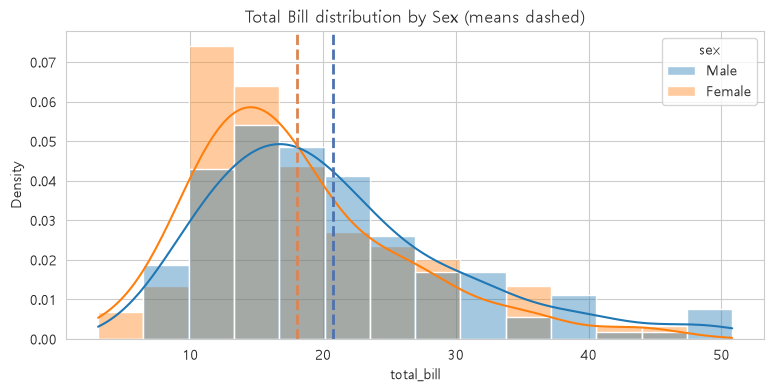

두 분포가 겹치는 정도가 클수록 '차이가 우연일' 여지가 큽니다. 평균차 2.69달러.


In [20]:
# [C4] [그림] t-test가 비교하는 '두 분포' — 남녀 결제 금액
fig, ax = plt.subplots(figsize=(9, 4))                            # 그래프 하나를 그릴 도화지 준비
sns.histplot(data=tips, x="total_bill", hue="sex", kde=True, stat="density",  # 히스토그램 — 값이 어디에 몰려 있나
             common_norm=False, alpha=0.4, ax=ax)
ax.axvline(male.mean(),   color="#4C72B0", ls="--", lw=2)
ax.axvline(female.mean(), color="#DD8452", ls="--", lw=2)
ax.set_title("Total Bill distribution by Sex (means dashed)")
plt.show()
print(f"두 분포가 겹치는 정도가 클수록 '차이가 우연일' 여지가 큽니다. 평균차 {male.mean()-female.mean():.2f}달러.")

> **읽는 법(그림):** 두 분포가 상당히 **겹칩니다.** 평균선(점선)은 남성이 오른쪽이지만, 분포가 넓게 포개져 있어 "차이가 _얼마나 확실한가_"는 숫자(검정)로 따져야 합니다. t-test는 바로 _"이 정도 겹침에서 평균차가 우연일 확률"_ 을 계산하는 것입니다.

> 📌 **다른 산업에서는?** 2표본 t-test는 마케팅(캠페인 A vs B 구매액), 제조(라인1 vs 라인2 불량 수치), 헬스케어(약 vs 위약 효과)에서 *두 집단의 평균 차이*를 판정하는 가장 기본 도구입니다.

## 도식 · p-value는 t 분포의 꼬리 면적

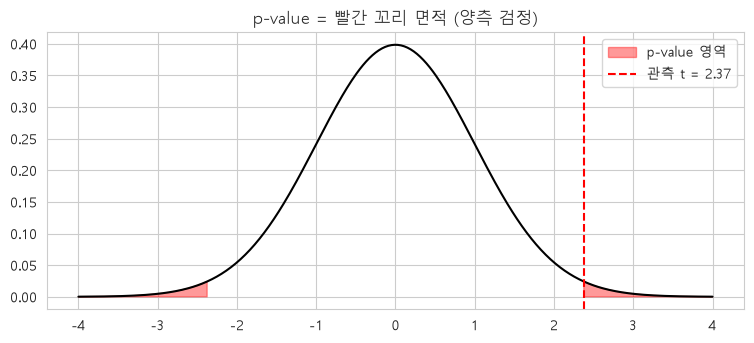

관측 t보다 더 극단적인 값이 H0(차이 없음)에서 나올 확률 = p-value


In [21]:
# [C5] [도식] p-value = t 분포에서 '관측값보다 극단적인' 꼬리 면적
dfree = len(male) + len(female) - 2
xx = np.linspace(-4, 4, 400)                                      # 구간을 균등 간격으로 쪼갠 x축 값
t_obs, _ = stats.ttest_ind(male, female, equal_var=False)         # 두 독립 집단의 평균 비교 (equal_var=False면 Welch)
fig, ax = plt.subplots(figsize=(9, 3.6))                          # 그래프 하나를 그릴 도화지 준비
ax.plot(xx, stats.t.pdf(xx, dfree), "k", lw=1.5)
ax.fill_between(xx, stats.t.pdf(xx, dfree), where=(np.abs(xx) >= abs(t_obs)),  # 곡선 아래 영역을 색으로 채움(= 면적은 확률)
                color="red", alpha=0.4, label="p-value 영역")
ax.axvline(t_obs, color="red", ls="--", label=f"관측 t = {t_obs:.2f}")  # 세로 기준선 표시
ax.set_title("p-value = 빨간 꼬리 면적 (양측 검정)"); ax.legend(); plt.show()
print("관측 t보다 더 극단적인 값이 H0(차이 없음)에서 나올 확률 = p-value")

> **읽는 법(그림):** p-value는 신비한 숫자가 아니라 **"H0가 참일 때 이만큼 극단적인 t가 나올 꼬리 확률"** 입니다. 관측 t가 분포 중심에서 멀수록(꼬리로 갈수록) 면적(p)이 작아져 H0를 의심하게 됩니다.

### 📖 잠깐 — t 분포는 왜 정규분포가 아닌가

위 그림의 검은 곡선은 정규분포가 아니라 **t 분포**입니다. 이유는 이렇습니다. 우리는 모표준편차 $\sigma$를 모르기 때문에 표본에서 추정한 $s$를 대신 씁니다. 그 추정에도 오차가 있으니, 불확실성을 한 겹 더 반영해 **정규분포보다 꼬리가 두꺼운** 분포를 씁니다. 그 두께를 정하는 것이 **자유도(df)** 입니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/4/41/Student_t_pdf.svg" width="620" alt="Student t pdf.svg">

자유도(ν)에 따른 t 분포. 자유도가 작으면 꼬리가 두껍고(극단값이 더 잘 나온다고 봄), 자유도가 커지면 점점 표준정규분포에 가까워집니다.

> 🖼️ **그림 출처** — Wikimedia Commons, `Student t pdf.svg` (CC BY 3.0) · 원본·라이선스 상세: https://commons.wikimedia.org/wiki/File:Student_t_pdf.svg

> 💡 **실무 감각:** 표본이 작을 때(예: n=10) t 분포의 두꺼운 꼬리는 "이 정도 차이로는 함부로 유의하다고 하지 말라"는 신중함으로 작동합니다. 표본이 커지면(n ≳ 30) t와 정규는 거의 구별되지 않습니다.

> **읽는 법:** p가 0.05보다 작아 "남녀 결제 금액에 차이가 있다"고 판정했습니다. 하지만 이건 _"차이가 있다/없다"_ 만 말할 뿐, **차이가 얼마나 큰지·실무적으로 중요한지는 말해주지 않습니다.** 그 한계가 Part 7의 동기입니다.

> ✅ **가정 체크리스트 — 2표본 t-test를 쓰려면**
>
> - [ ] 두 집단이 **독립**인가 (서로 다른 사람들인가)
> - [ ] 각 집단이 대략 **정규**에 가깝거나 표본이 충분히 큰가(n≳30, 중심극한정리)
> - [ ] 등분산인가? — 모르면 **Welch t-test**(`equal_var=False`)가 안전한 기본값

> ⚠️ **흔한 오해 / 함정**
> ❗ **"p < 0.05이면 H1(차이 있다)이 참으로 증명됐다" — 아닙니다.** p는 _"H0가 참일 때 이 데이터가 나올 확률"_ 일 뿐, 가설이 참일 확률이 아닙니다. 또 _"p가 작다 = 차이가 크다"_ 도 아닙니다(Part 7).

## 한쪽만 볼까, 양쪽 다 볼까 — 단측검정과 양측검정

가설의 **방향**을 어떻게 잡느냐에 따라 검정이 둘로 나뉩니다.

- **양측검정(Two-Tailed):** "다르다"만 주장합니다. $H_1: \mu \neq \mu_0$. 차이가 _어느 쪽이든_ 잡아냅니다. **기본값**입니다.
- **단측검정(One-Tailed):** "더 크다"(또는 "더 작다")처럼 _방향까지_ 주장합니다. $H_1: \mu > \mu_0$. 한쪽 꼬리만 봅니다.

| 구분 | 대립가설                         | 언제 쓰나                 | 같은 데이터의 p |
| ---- | -------------------------------- | ------------------------- | --------------- |
| 양측 | $\mu \neq \mu_0$                 | 방향을 모를 때 (기본)     | 더 큼(보수적)   |
| 단측 | $\mu > \mu_0$ 또는 $\mu < \mu_0$ | 방향이 _사전에_ 정해질 때 | 양측의 약 절반  |

> ⚠️ **함정:** 데이터를 _본 뒤에_ "큰 쪽이 유의하네" 하며 단측으로 바꾸면 안 됩니다(p를 인위적으로 반토막 내는 셈입니다). 단측은 **데이터를 보기 전에** 방향이 정해질 때만 씁니다. 헷갈리면 **양측**이 안전합니다.

In [22]:
# [C6] [확인] 같은 데이터 — 양측 vs 단측 p-value
g_dinner = tips[tips["time"] == "Dinner"]["total_bill"]
g_lunch  = tips[tips["time"] == "Lunch"]["total_bill"]

t_two = stats.ttest_ind(g_dinner, g_lunch)                          # 양측 (기본)
t_one = stats.ttest_ind(g_dinner, g_lunch, alternative="greater")  # 단측 (저녁 > 점심)
print(f"양측검정 : t = {t_two.statistic:6.3f},  p = {t_two.pvalue:.4f}")
print(f"단측검정 : t = {t_one.statistic:6.3f},  p = {t_one.pvalue:.4f}   (방향 가설: 저녁 > 점심)")
print()
print("→ 같은 t값인데 단측 p가 양측 p의 약 절반입니다(한쪽 꼬리만 보므로).")

양측검정 : t =  2.898,  p = 0.0041
단측검정 : t =  2.898,  p = 0.0021   (방향 가설: 저녁 > 점심)

→ 같은 t값인데 단측 p가 양측 p의 약 절반입니다(한쪽 꼬리만 보므로).


> ➕ **더 알고 싶다면 — p-value를 한 문장으로:** p는 _"귀무가설($H_0$)이 참이라고 가정했을 때, 지금 관측한 것만큼 극단적인 결과가 나올 확률"_ 입니다. 그래서 p가 작다는 건 "$H_0$ 아래에선 좀처럼 안 나올 데이터가 나왔다 → $H_0$가 의심스럽다"는 뜻이지, **"$H_0$가 참일 확률"이 아닙니다.** 이 둘을 혼동하는 게 통계에서 가장 흔한 오해입니다.

## ⌨️ 백문이 불여일타! (1) — 점심 vs 저녁 결제 금액 2표본 t-test

```
[문제]
식당의 점심(Lunch) vs 저녁(Dinner) 결제 금액에 차이가 있을까요?
1) (따라하기) tips를 time으로 나눠 2표본 t-test를 수행해보세요.
2) (해석) p-value로 6단계의 [5]·[6]을 직접 써보세요.
3) (생각해보기) 만약 표본이 10건씩이었다면 같은 결론이 나왔을까요? (Part 4에서 답)
```

In [32]:
# [C7] ⌨️ 백문이 불여일타! (1) — 점심 vs 저녁 결제 금액 2표본 t-test

# [백문이 불여일타 (1)] 점심 vs 저녁 결제 금액 — 2표본 t-test
lunch  = tips[tips["time"] == "Lunch"]["total_bill"]
dinner = tips[tips["time"] == "Dinner"]["total_bill"]
alpha  = 0.05

# 1) 두 독립 집단 평균 비교 → 2표본 t-test (분산이 같다고 확신할 수 없으니 Welch)
t, p = stats.ttest_ind(dinner, lunch, equal_var=False)

print(f"[1-2] H0: 점심=저녁  vs  H1: 점심≠저녁")
print(f"      점심 평균 {lunch.mean():.2f} (n={len(lunch)})  /  저녁 평균 {dinner.mean():.2f} (n={len(dinner)})")
print(f"[4]   t = {t:.2f},  p = {p:.4f}")

# 2) [5] 판정 · [6] 해석
print(f"[5]   p {'<' if p < alpha else '≥'} α(={alpha}) → H0 {'기각: 차이 있다' if p < alpha else '기각 못함'}")
print(f"[6]   해석: 저녁 결제 금액이 점심보다 평균 {dinner.mean() - lunch.mean():.2f}달러 높고, "
      f"이 차이는 통계적으로 유의합니다. (단, '얼마나' 큰지는 효과 크기로 따로 확인)")

# 3) (생각해보기) 표본이 10건씩이었다면? → 10건씩 1000번 뽑아 검정해보기
np.random.seed(42)
p_small = [stats.ttest_ind(dinner.sample(10), lunch.sample(10), equal_var=False).pvalue
           for _ in range(1000)]
print(f"\n[3]   10건씩 1000번 검정 → p < 0.05가 나온 비율: {np.mean(np.array(p_small) < alpha):.1%}")

# 3) 답:
#   같은 결론이 나오기 어렵다. 실제 평균 차이(약 3.6달러)는 그대로여도,
#   표본이 작으면 표준오차가 커져서 t값이 작아지고 p-value가 커진다.
#   즉 차이가 실제로 있어도 검정이 그 차이를 잡아낼 확률(= 검정력)이 낮아져,
#   'H0 기각 못함'이 나오기 쉽다. (2종 오류 → Part 4의 검정력 내용)

[1-2] H0: 점심=저녁  vs  H1: 점심≠저녁
      점심 평균 17.17 (n=68)  /  저녁 평균 20.80 (n=176)
[4]   t = 3.12,  p = 0.0022
[5]   p < α(=0.05) → H0 기각: 차이 있다
[6]   해석: 저녁 결제 금액이 점심보다 평균 3.63달러 높고, 이 차이는 통계적으로 유의합니다. (단, '얼마나' 큰지는 효과 크기로 따로 확인)

[3]   10건씩 1000번 검정 → p < 0.05가 나온 비율: 11.2%


<details>
<summary>(클릭) 💡 힌트</summary>

- 먼저 불리언 인덱싱으로 `time` 값이 `"Lunch"`인 행과 `"Dinner"`인 행의 `total_bill`을 각각 뽑아 두 시리즈를 만들어보세요.
- 두 독립 집단의 평균 비교는 [C3]에서 본 `stats.ttest_ind()`입니다 — 분산이 같다고 확신할 수 없으니 `equal_var=False`(Welch)가 안전합니다.
- [5]·[6]단계는 p와 유의수준 0.05를 비교해 "기각/기각 못함"을 판정하고, 비즈니스 해석 한 줄로 마무리해보세요. 3)번 답은 주석으로 정리해보세요.

</details>

## 🚦 짚고 넘어가기 — Part 3 가설검정 6단계

다음 질문에 답할 수 있으면 다음 Part로 넘어가세요. 틀려도 괜찮습니다.

1. $H_0$와 $H_1$은 각각 무엇을 뜻하나요?
2. p-value를 한 문장으로 설명해보세요 ("H0가 참일 때 …").
3. "p < 0.05라서 차이가 있다"고만 보고하면 무엇을 놓치나요?

> 💡 **다음 Part 예고:** 검정은 _틀릴 수도_ 있습니다 — 없는 차이를 있다고 하거나(1종), 있는 차이를 놓치거나(2종). 그 두 오류와 *검정력*을 다음 Part에서 봅니다.

---

# Part 4. 1종·2종 오류와 검정력

검정은 확률에 기반한 *판단*이라, 늘 맞지는 않습니다. **두 가지 방식으로 틀릴 수 있습니다.**

> ❓ **이 파트에서 답할 질문:** 검정이 틀리는 두 가지 방식은 무엇이고, "진짜 차이를 잡아내는 힘"은 어떻게 키울까?

## 💡 쉽게 말하면 — 화재경보기

```
실제로 불이 없음 + 경보 울림  → 오경보 (1종 오류, α)
실제로 불이 남   + 경보 안 울림 → 못 잡음 (2종 오류, β)
실제로 불이 남   + 경보 울림   → 제대로 잡음 (검정력 = 1 − β)
```

<img src="https://upload.wikimedia.org/wikipedia/commons/e/e7/False_positives_and_false_negatives.svg" width="560" alt="False positives and false negatives.svg">

**거짓 양성(false positive = 1종 오류)** 과 **거짓 음성(false negative = 2종 오류)**. 왼쪽 그림처럼 없는 것을 있다고 하는 오류와, 오른쪽처럼 있는 것을 놓치는 오류는 서로 다른 종류의 실수입니다.

> 🖼️ **그림 출처** — Wikimedia Commons, `False positives and false negatives.svg` (CC BY-SA 4.0) · 원본·라이선스 상세: https://commons.wikimedia.org/wiki/File:False_positives_and_false_negatives.svg

## 두 오류와 검정력

|                             | $H_0$ 참 (차이 없음)   | $H_0$ 거짓 (차이 있음)     |
| --------------------------- | ---------------------- | -------------------------- |
| **기각** ("차이 있다")      | ❌ 1종 오류 ($\alpha$) | ✅ 옳음 (검정력 $1-\beta$) |
| **기각 못함** ("차이 없다") | ✅ 옳음                 | ❌ 2종 오류 ($\beta$)      |

- $\alpha$를 낮추면(더 보수적) 1종 오류↓ 이지만 2종 오류↑ (둘은 trade-off)
- **검정력↑ 방법:** 표본 크기↑, 효과가 클수록, 측정 잡음↓
- 보통 검정력 0.8(80%) 이상을 목표로 합니다.

> ⚠️ **두 오류의 비용은 상황마다 다릅니다.** 신약 승인에서 1종 오류(효과 없는 약을 통과)는 환자에게 위험하고, 암 검진에서 2종 오류(있는 병을 놓침)는 치명적입니다. 그래서 $\alpha$와 목표 검정력은 *분석 전에, 도메인 사정에 맞춰* 정합니다 — 결과를 보고 고치는 것이 아닙니다.

## 시뮬레이션 · 1종 오류율과 검정력을 직접 세어보기

In [36]:
# [C8] 1종·2종 오류 시뮬레이션 — '정답'을 알아야 보이므로 통제 합성(seed 고정)
np.random.seed(42)                                                # 재현성: 난수를 항상 같게 고정
N_SIM, n = 2000, 30

# (A) 진짜 차이가 '없을' 때 → 유의 판정 비율 ≈ α (1종 오류율)
false_pos = np.mean([stats.ttest_ind(np.random.normal(50, 10, n),  # 두 독립 집단의 평균 비교 (equal_var=False면 Welch)
                                      np.random.normal(50, 10, n)).pvalue < 0.05
                     for _ in range(N_SIM)])
# (B) 진짜 차이가 '있을' 때(평균차 5) → 유의 판정 비율 = 검정력
power = np.mean([stats.ttest_ind(np.random.normal(55, 10, n),     # 두 독립 집단의 평균 비교 (equal_var=False면 Welch)
                                 np.random.normal(50, 10, n)).pvalue < 0.05
                for _ in range(N_SIM)])

print(f"진짜 차이 없음 → 유의 판정 {false_pos:5.1%}   (≈ α=5%, 1종 오류)")
print(f"진짜 차이 있음 → 유의 판정 {power:5.1%}   (= 검정력 ; 나머지 {1-power:.0%}는 2종 오류)")

진짜 차이 없음 → 유의 판정  4.6%   (≈ α=5%, 1종 오류)
진짜 차이 있음 → 유의 판정 46.8%   (= 검정력 ; 나머지 53%는 2종 오류)


## 그림으로 · 검정력 곡선 — 표본이 커질수록

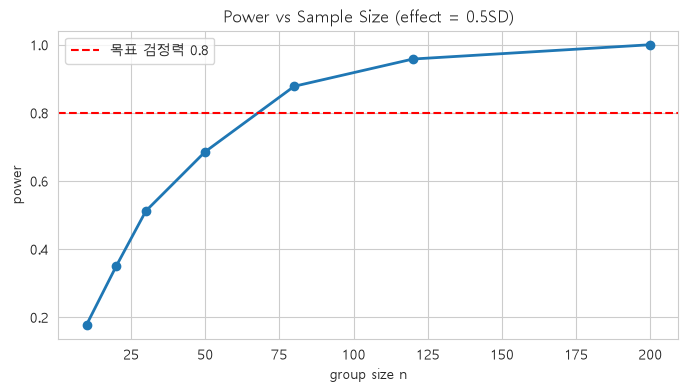

같은 효과라도 표본이 커지면 검정력이 빠르게 1.0에 다가갑니다.


In [ ]:
# [C9] [그림] 검정력 곡선 — 표본이 커질수록 진짜 차이를 잘 잡는다
np.random.seed(42)                                                # 재현성: 난수를 항상 같게 고정
ns = [10, 20, 30, 50, 80, 120, 200]
powers = [np.mean([stats.ttest_ind(np.random.normal(55, 10, n),   # 두 독립 집단의 평균 비교 (equal_var=False면 Welch)
                                   np.random.normal(50, 10, n)).pvalue < 0.05
                   for _ in range(500)]) for n in ns]
fig, ax = plt.subplots(figsize=(8, 4))                            # 그래프 하나를 그릴 도화지 준비
ax.plot(ns, powers, "o-", lw=2)
ax.axhline(0.8, color="red", ls="--", label="목표 검정력 0.8")         # 가로 기준선 표시
ax.set_xlabel("group size n"); ax.set_ylabel("power")
ax.set_title("Power vs Sample Size (effect = 0.5SD)"); ax.legend(); plt.show()
print("같은 효과라도 표본이 커지면 검정력이 빠르게 1.0에 다가갑니다.")

> **읽는 법(그림):** 검정력 곡선이 우상향합니다 — 표본 30 부근에선 진짜 차이를 놓칠(2종 오류) 위험이 꽤 있지만, 100을 넘기면 거의 확실히 잡아냅니다. **실험 설계 전에 "검정력 0.8을 위한 표본 크기"를 미리 정하는 것**이 좋은 습관이에요(A/B 설계로 연결).

> 📌 **다른 산업에서는?** 검정력 분석은 임상시험(필요 환자 수 산정), A/B 테스트(필요 트래픽 산정), 품질검사(검출력 설계)에서 _"표본이 얼마나 필요한가"_ 를 정하는 핵심 단계입니다.

## 도식 · 1종·2종 오류의 trade-off

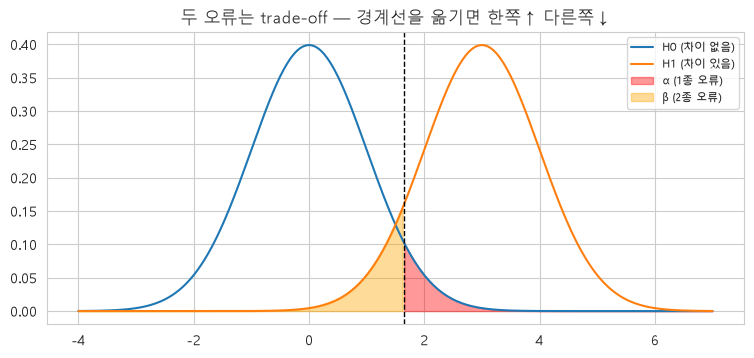

In [37]:
# [C10] [도식] 1종(α)·2종(β) 오류 — 두 가설 분포의 겹침
xx = np.linspace(-4, 7, 400)                                      # 구간을 균등 간격으로 쪼갠 x축 값
crit = stats.norm.ppf(0.95)
fig, ax = plt.subplots(figsize=(9, 3.8))                          # 그래프 하나를 그릴 도화지 준비
ax.plot(xx, stats.norm.pdf(xx, 0, 1), label="H0 (차이 없음)")
ax.plot(xx, stats.norm.pdf(xx, 3, 1), label="H1 (차이 있음)")
ax.fill_between(xx, stats.norm.pdf(xx, 0, 1), where=(xx >= crit), color="red",    alpha=0.4, label="α (1종 오류)")  # 곡선 아래 영역을 색으로 채움(= 면적은 확률)
ax.fill_between(xx, stats.norm.pdf(xx, 3, 1), where=(xx <  crit), color="orange", alpha=0.4, label="β (2종 오류)")  # 곡선 아래 영역을 색으로 채움(= 면적은 확률)
ax.axvline(crit, color="k", ls="--", lw=1)                        # 세로 기준선 표시
ax.set_title("두 오류는 trade-off — 경계선을 옮기면 한쪽↑ 다른쪽↓")
ax.legend(fontsize=8); plt.show()

> **읽는 법(그림):** 검은 점선(판정 경계)을 오른쪽으로 옮기면 빨강(α)은 줄지만 주황(β)이 커집니다 — **1종과 2종 오류는 동시에 줄일 수 없는 trade-off** 입니다. 두 분포가 더 멀어지거나(효과↑) 좁아지면(표본↑) 둘 다 줄일 수 있습니다.

> **읽는 법:** 차이가 없을 때도 약 5%는 "유의"가 나옵니다 — 이게 우리가 감수하는 1종 오류율($\alpha$)입니다. 차이가 있을 때 잡아내는 비율이 **검정력**이고, 못 잡은 나머지가 2종 오류입니다. 표본이 작으면(n=30) 검정력이 생각보다 낮을 수 있습니다.

> ⚠️ **흔한 오해 / 함정**
> ❗ **"p ≥ 0.05라서 차이가 없다(H0가 참이다)" — 아닙니다.** 차이가 _있어도_ 표본이 작아 **검정력이 부족하면** 못 잡습니다. "차이 없음"이 아니라 _"차이가 있다는 증거가 부족함"_ 일 뿐입니다.

## ⌨️ 백문이 불여일타! (2) — 표본 크기에 따른 검정력 변화

```
[문제]
1) (따라하기) 위 (B) 시뮬레이션에서 n을 30 → 100으로 바꿔 검정력이 어떻게 변하는지 보세요.
2) (해석) 표본을 키우면 검정력이 오르는 이유를 한 줄로 설명해보세요.
3) (생각해보기) "효과는 작지만 표본이 매우 크면" p는 어떻게 될까요? (Part 7 복선)
```

In [38]:
# [C11] ⌨️ 백문이 불여일타! (2) — 표본 크기에 따른 검정력 변화 시뮬레이션

# 여기에 코드를 작성하세요

# 1) (B) 시뮬레이션에서 n만 바꿔 검정력 비교 (진짜 평균차 5, 표준편차 10)
np.random.seed(42)
N_SIM = 2000

for n in [30, 100, 300]:
    hits = 0
    for _ in range(N_SIM):
        a = np.random.normal(55, 10, n)            # 진짜 평균 55
        b = np.random.normal(50, 10, n)            # 진짜 평균 50 → 실제로 차이가 '있음'
        if stats.ttest_ind(a, b).pvalue < 0.05:    # 유의하다고 판정했으면
            hits += 1                              # 차이를 '잡아낸' 횟수 +1
    power = hits / N_SIM
    print(f"n = {n:3d} → 검정력 {power:5.1%}  (2종 오류 {1 - power:5.1%})")

# 3) 효과는 아주 작은데(평균차 0.5, 표준편차 10) 표본이 매우 크면?
print()
np.random.seed(42)
for n in [100, 1000, 10000, 100000]:
    a = np.random.normal(50.5, 10, n)
    b = np.random.normal(50.0, 10, n)
    p = stats.ttest_ind(a, b).pvalue
    print(f"n = {n:6d} → 평균차 {a.mean() - b.mean():+.2f}, p = {p:.4g}")

# 2) 해석: 표본이 커지면 표준오차(σ/√n)가 줄어 같은 크기의 차이도 t값이 커지므로,
#          진짜 차이를 '우연'과 구분해 잡아낼 확률(검정력)이 올라간다.
#
# 3) 생각해보기: 효과가 아주 작아도 매우 크면 p가 0에 가까워져
#          '통계적으로 유의'하다고 나온다. 하지만 실제로는 의미 없는 수준의 차이일 수 있다.
#          → p-value는 '차이가 있는지'만 말해 줄 뿐, '차이가 얼마나 큰지'는 알려주지 않는다.
#            그래서 효과 크기를 함


n =  30 → 검정력 48.0%  (2종 오류 52.0%)
n = 100 → 검정력 94.3%  (2종 오류  5.7%)
n = 300 → 검정력 100.0%  (2종 오류  0.0%)

n =    100 → 평균차 -0.76, p = 0.5637
n =   1000 → 평균차 +0.73, p = 0.09909
n =  10000 → 평균차 +0.21, p = 0.1383
n = 100000 → 평균차 +0.52, p = 5.482e-31


<details>
<summary>(클릭) 💡 힌트</summary>

- [C8]의 (B) 검정력 시뮬레이션 코드를 가져와 `n` 값만 바꾸면 됩니다 — `for n in [30, 100, 300]:`처럼 반복문으로 한 번에 비교하면 편합니다.
- 재현성을 위해 반복 전에 `np.random.seed(42)`를 먼저 호출해보세요.
- 2)·3)번 답은 코드 아래 주석으로 정리해보세요 — 표본이 커지면 표준오차가 줄어 같은 크기의 차이도 더 또렷해진다는 점이 열쇠입니다.

</details>

## 🚦 짚고 넘어가기 — Part 4 오류와 검정력

1. 1종 오류와 2종 오류를 화재경보기 비유로 설명할 수 있나요?
2. 검정력을 높이는 방법 세 가지는?
3. "p ≥ 0.05 = 차이 없음 증명"이 왜 틀린 말인가요?

> 💡 **다음 Part 예고:** 이제 절차와 오류를 알았으니, 실제 검정 도구인 **t-test 세 가지**(1표본·2표본·대응표본)를 상황별로 골라 쓰는 법을 봅니다.

---

# Part 5. t-test 세 가지 — 1표본·2표본·대응표본

t-test는 하나가 아니라 **상황에 따라 세 가지**입니다. 상황을 잘못 고르면 결과가 틀려요.

> ❓ **이 파트에서 답할 질문:** 어떤 상황에 어떤 t-test를 써야 할까?

## 💡 쉽게 말하면 — 세 가지 t-test 고르기

```
1표본 t-test : 한 집단을 '기준값'과 비교   (이 종 체중이 5kg과 다른가?)
2표본 t-test : 독립된 두 집단을 비교        (남 vs 여 결제 금액)
대응표본 t-test: 같은 대상의 '전 vs 후' 비교 (같은 기업의 87년 vs 88년 불량률)
```

## 수식과 적용 상황

1표본 t-통계량:

$$t = \frac{\bar{x} - \mu_0}{s / \sqrt{n}}$$

- $\bar{x}$: 표본평균 · $\mu_0$: 비교 기준값 · $s$: 표본표준편차 · $n$: 표본 크기
- 직관: **"차이가 _흔들림(표준오차)_ 대비 얼마나 큰가?"** — 분자(차이)가 크고 분모(흔들림)가 작을수록 t가 큼.

| 종류        | 언제               | scipy 함수                                   |
| ----------- | ------------------ | -------------------------------------------- |
| 1표본       | 한 집단 vs 기준값  | `stats.ttest_1samp`                          |
| 2표본(독립) | 서로 다른 두 집단  | `stats.ttest_ind` (Welch: `equal_var=False`) |
| 대응표본    | 같은 대상 전/후·짝 | `stats.ttest_rel`                            |

## 예제 · t-test 세 가지를 실데이터로 한 번에

In [39]:
# [C12] t-test 세 가지를 한 번에 — 모두 실데이터로
# (1) 1표본: Gentoo 펭귄 체중이 기준 5000g과 다른가?
gentoo = penguins[penguins["species"] == "Gentoo"]["body_mass_g"]
t1, p1 = stats.ttest_1samp(gentoo, 5000)                          # 한 집단 평균을 기준값과 비교
print(f"[1표본]  Gentoo {gentoo.mean():.0f}g vs 기준 5000g → t={t1:.2f}, p={p1:.3f}")

# (2) 2표본(독립): 남 vs 여 결제 금액 (Welch)
male   = tips[tips["sex"] == "Male"]["total_bill"]
female = tips[tips["sex"] == "Female"]["total_bill"]
t2, p2 = stats.ttest_ind(male, female, equal_var=False)           # 두 독립 집단의 평균 비교 (equal_var=False면 Welch)
print(f"[2표본]  남 {male.mean():.2f} vs 여 {female.mean():.2f} → t={t2:.2f}, p={p2:.3f}")

# (3) 대응표본: '같은 기업'의 1987 → 1988 불량률 (jtrain, 실데이터)
t3, p3 = stats.ttest_rel(before, after)                           # 대응표본 t-test = '차이'에 대한 1표본 t-test
print(f"[대응]   기업 {len(before)}곳의 불량률 {before.mean():.2f}% → {after.mean():.2f}%"
      f" → t={t3:.2f}, p={p3:.4f}")
print(f"         (기업별 변화량 평균 = {(after - before).mean():+.2f}%p,"
      f" 감소한 기업 {int((after < before).sum())}곳 / 증가 {int((after > before).sum())}곳)")

[1표본]  Gentoo 5076g vs 기준 5000g → t=1.67, p=0.097
[2표본]  남 20.74 vs 여 18.06 → t=2.37, p=0.019
[대응]   기업 54곳의 불량률 4.61% → 3.79% → t=2.52, p=0.0147
         (기업별 변화량 평균 = -0.82%p, 감소한 기업 34곳 / 증가 16곳)


## 그림으로 · 대응표본 — 같은 기업의 전후를 선으로 잇기

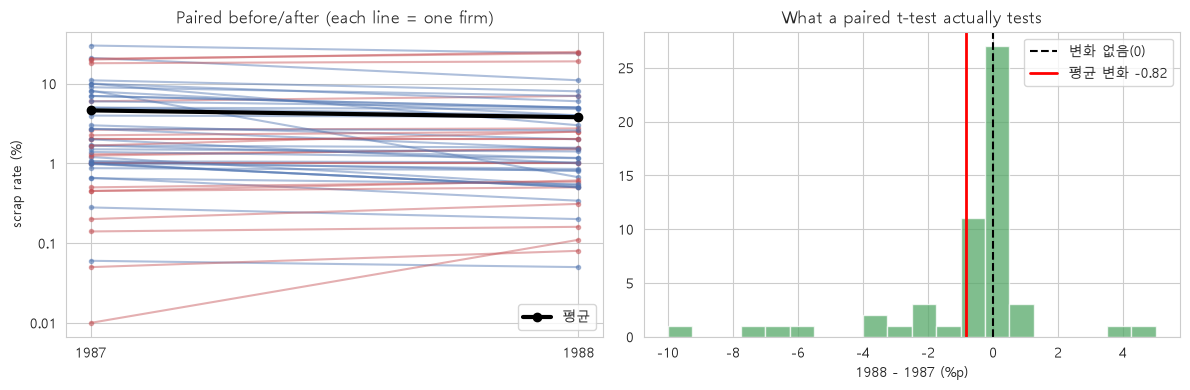

대응표본 t-test는 두 집단을 비교하는 게 아니라, '차이(오른쪽 분포)의 평균이 0인가'를 검정합니다.


In [42]:
# [C13] [그림] 대응표본 — 같은 기업의 전/후를 선으로 잇기
fig, axes = plt.subplots(1, 2, figsize=(12, 4))                   # 그림 한 장에 그래프 2개(1행 2열)

# (왼쪽) 기업별 전→후 연결선
for b, a in zip(before, after):
    color = "#4C72B0" if a < b else "#C44E52"      # 파랑=감소, 빨강=증가
    axes[0].plot([0, 1], [b, a], color=color, alpha=0.45, marker="o", ms=3)
axes[0].plot([0, 1], [before.mean(), after.mean()], color="black", lw=3, marker="o", label="평균")
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["1987", "1988"])
axes[0].set_ylabel("scrap rate (%)"); axes[0].set_yscale("log")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))   # 10⁻¹ 대신 0.1처럼 표시
axes[0].set_title("Paired before/after (each line = one firm)"); axes[0].legend()

# (오른쪽) 대응표본 t-test가 실제로 보는 것 = '차이'의 분포
diff = after - before
axes[1].hist(diff, bins=20, color="#55A868", alpha=0.75)
axes[1].axvline(0, color="black", ls="--", label="변화 없음(0)")      # 세로 기준선 표시
axes[1].axvline(diff.mean(), color="red", lw=2, label=f"평균 변화 {diff.mean():+.2f}")  # 세로 기준선 표시
axes[1].set_xlabel("1988 - 1987 (%p)"); axes[1].set_title("What a paired t-test actually tests")
axes[1].legend()
plt.tight_layout(); plt.show()                                    # 그래프 간격 자동 정리 후 출력

print("대응표본 t-test는 두 집단을 비교하는 게 아니라, '차이(오른쪽 분포)의 평균이 0인가'를 검정합니다.")

> **읽는 법(그림):** 왼쪽 선 하나하나가 *한 기업*의 1987→1988 변화입니다(파랑=감소, 빨강=증가). 기업마다 불량률 수준이 워낙 달라서(로그 축을 쓴 이유) 2표본으로 비교했다면 그 **개체 간 차이가 잡음**이 됐을 겁니다. 대응표본은 같은 기업 *내부의 변화*만 보므로 그 잡음이 상쇄됩니다.
>
> 오른쪽이 그 핵심입니다 — 대응표본 t-test는 사실 **"차이(after − before)의 평균이 0인가"** 를 묻는 *1표본 t-test*입니다. 그래서 짝지을 수만 있다면 검정력이 훨씬 좋습니다.
>
> ⚠️ **그런데 이 감소가 "훈련 프로그램의 효과"일까요?** 아직 그렇게 말할 수 없습니다. 1987→1988 사이에 경기·설비·학습효과 등 *시간이 만든 변화*가 모두 섞여 있으니까요. 이 문제(전후 비교의 함정)를 정면으로 다루는 것이 **D017의 이중차분(DiD)** 입니다. 오늘은 "변화가 통계적으로 유의한가"까지만 말합니다.

> 📌 **다른 산업에서는?** 대응표본은 교육(사전·사후 점수), 의료(투약 전후 혈압), 제조(개선 전후 불량률)처럼 *같은 대상의 변화*를 볼 때 강력합니다.

## 그림으로 · 2표본 — violin으로 분포까지 보기

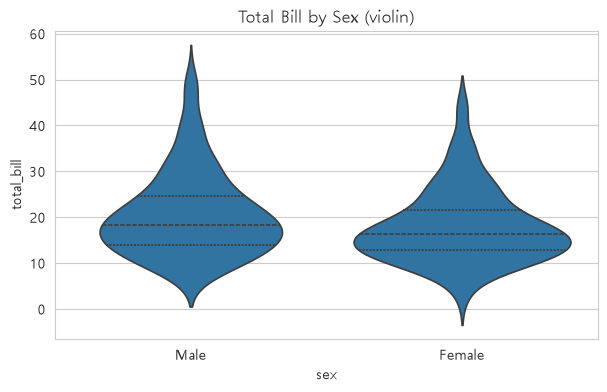

In [41]:
# [C14] [그림] 2표본 — 집단별 분포를 violin으로 한눈에
fig, ax = plt.subplots(figsize=(7, 4))                            # 그래프 하나를 그릴 도화지 준비
sns.violinplot(data=tips, x="sex", y="total_bill", inner="quartile", ax=ax)  # violin — 분포의 '모양'까지 보여줌
ax.set_title("Total Bill by Sex (violin)"); plt.show()

> **읽는 법(그림):** violin은 분포 _모양_ 까지 보여줍니다 — 두 집단 모두 오른쪽 꼬리(고액 결제)가 있고 폭이 넓게 겹칩니다. 평균은 다르지만 _겹침이 커서_ 효과 크기는 작을 것임을 미리 짐작할 수 있어요(Part 7에서 확인).

> **읽는 법:** 결과가 셋 다 같지 않습니다 — 이게 오히려 좋은 학습거리입니다.
>
> - **1표본**(Gentoo vs 5,000g): p ≈ 0.10으로 **유의하지 않습니다.** 표본평균이 5,076g으로 기준보다 높긴 하지만, 이 정도 차이는 우연으로도 나올 수 있다는 뜻입니다("차이가 없다"는 증명이 아니라 *증거 부족*입니다).
> - **2표본**(남 vs 여): p ≈ 0.02로 유의합니다.
> - **대응표본**(같은 기업 87→88): p ≈ 0.015로 유의합니다.
>
> 특히 **대응표본**은 *같은 기업*을 전후로 비교하므로 개체 간 차이(원래 불량률 수준의 차이)를 상쇄해 **작은 변화도 민감하게** 잡아냅니다 — 그래서 "전후 설계"가 강력합니다.
>
> 💡 다만 대응표본의 강점은 *짝을 지을 수 있을 때만* 얻어집니다. 두 집단이 서로 다른 대상이라면(남성 vs 여성) 억지로 짝지어선 안 되고, 반드시 2표본 t-test를 써야 합니다.

> ✅ **가정 체크리스트 — t-test**
>
> - [ ] **독립성**: 2표본은 두 집단이 독립 / 대응표본은 _짝지어진_ 관측
> - [ ] **정규성**: 각 집단(또는 대응표본의 _차이_)이 대략 정규 (n≳30이면 완화)
> - [ ] **등분산**: 2표본에서 분산이 비슷한가 — 모르면 **Welch**가 안전

## 분산이 다르면? — Student's t와 Welch's t

2표본 t-test에는 숨은 가정이 하나 있습니다: **두 집단의 분산(퍼짐)이 같다**(등분산, equal variance). 그런데 현실 데이터는 이 가정이 자주 깨집니다(한 집단이 더 들쭉날쭉합니다).

| 방법                               | 등분산 가정 | 특징                                 |
| ---------------------------------- | ----------- | ------------------------------------ |
| **Student's t** (`equal_var=True`) | 가정함      | 가정이 맞으면 약간 더 강력           |
| **Welch's t** (`equal_var=False`)  | 가정 안 함  | 분산이 달라도 안전 — **실무 기본값** |

> 📌 **실무에서는 Welch를 기본으로.** 등분산인지 미리 알기 어렵고, Welch는 등분산일 때도 거의 손해가 없기 때문입니다. `scipy`의 `ttest_ind`는 기본이 `equal_var=True`(Student)이므로, 실무에선 **`equal_var=False`를 명시**하는 습관을 들이세요. (참고로 R의 `t.test`는 기본이 Welch입니다.)

In [43]:
# [C15] [비교] 등분산 가정 여부에 따른 2표본 t-test
np.random.seed(42)                                                # 재현성: 난수를 항상 같게 고정
a = np.random.normal(50,  5, 40)    # 퍼짐 작음
b = np.random.normal(53, 15, 40)    # 퍼짐 큼 (표준편차 약 3배)

student = stats.ttest_ind(a, b, equal_var=True)                   # 두 독립 집단의 평균 비교 (equal_var=False면 Welch)
welch   = stats.ttest_ind(a, b, equal_var=False)                  # 두 독립 집단의 평균 비교 (equal_var=False면 Welch)
print(f"두 집단 표준편차 : a = {a.std(ddof=1):.1f},  b = {b.std(ddof=1):.1f}")
print(f"Student's t : t = {student.statistic:6.3f},  p = {student.pvalue:.4f}   (등분산 가정)")
print(f"Welch's   t : t = {welch.statistic:6.3f},  p = {welch.pvalue:.4f}   (등분산 가정 안 함)")
print()
print("→ 분산이 다를수록 두 방법의 결과가 벌어집니다. 의심되면 Welch가 안전합니다.")

두 집단 표준편차 : a = 4.8,  b = 14.5
Student's t : t = -1.518,  p = 0.1330   (등분산 가정)
Welch's   t : t = -1.518,  p = 0.1356   (등분산 가정 안 함)

→ 분산이 다를수록 두 방법의 결과가 벌어집니다. 의심되면 Welch가 안전합니다.


## ⌨️ 백문이 불여일타! (3) — Adelie 체중 1표본 t-test

```
[문제]
1) (따라하기) Adelie 펭귄 체중이 기준 3700g과 다른지 1표본 t-test로 확인해보세요.
2) (해석) p-value로 판정을 써보세요.
3) (따라하기) 불량률의 '차이(after - before)'에 1표본 t-test(기준 0)를 적용해,
   [C12]의 대응표본 t-test 결과와 t·p가 같은지 확인해보세요.
4) (생각해보기) 2표본과 대응표본은 무엇이 다르고, 왜 대응표본이 더 민감할까요?
```

In [ ]:
# [C16] ⌨️ 백문이 불여일타! (3) — Adelie 체중 vs 기준 3700g 1표본 t-test

# 여기에 코드를 작성하세요

<details>
<summary>(클릭) 💡 힌트</summary>

- `penguins`에서 `species`가 `"Adelie"`인 행의 `body_mass_g`만 골라 시리즈로 만들어보세요.
- 기준값 하나와 비교하는 검정은 [C12]에서 본 `stats.ttest_1samp(시리즈, 기준값)`입니다.
- 3)번은 "서로 다른 두 집단인가, 같은 대상의 전/후인가"를 기준으로 생각해 주석으로 정리해보세요.

</details>

## 🚦 짚고 넘어가기 — Part 5 t-test 세 가지

1. 1표본·2표본·대응표본 t-test의 적용 상황을 각각 한 문장으로?
2. t 통계량의 분자·분모는 각각 무엇을 뜻하나요?
3. Welch t-test는 어떤 가정을 _덜_ 필요로 하나요?

> 💡 **다음 Part 예고:** 집단이 **셋 이상**이면 t-test를 반복해야 할까요? 그러면 위험합니다 — 그래서 한 번에 비교하는 **분산분석(ANOVA)** 이 등장합니다.

---

# Part 6. 여러 집단 비교 — 일원 ANOVA와 Tukey

펭귄은 종이 **셋**(Adelie·Chinstrap·Gentoo)입니다. "세 종의 체중이 다른가?"를 t-test로 풀려면 3번(쌍마다) 해야 하는데, 검정을 반복하면 **1종 오류가 누적**됩니다(우연히 유의가 나올 확률↑). 그래서 **한 번에** 비교하는 도구가 필요합니다.

> ❓ **이 파트에서 답할 질문:** 세 집단 이상의 평균이 다른지를 *한 번의 검정*으로 어떻게 판정할까?

## 💡 쉽게 말하면 — "집단 사이 vs 집단 안"

```
집단 사이 변동(between)이 크고  →  종마다 체중이 정말 다르다는 신호
집단 안 변동(within)이 작으면   →  같은 종 안에서는 비슷하다는 신호
F = (집단 사이 변동) / (집단 안 변동)  →  클수록 "집단 차이가 진짜"
```

> 💡 **왜 '분산분석(ANOVA)'이라 부르나요?** 평균을 비교하는 검정인데 이름에 '분산'이 들어가는 게 이상하죠. 비결은 위 식입니다 — 평균들이 벌어진 정도를 *분산*으로 재고, 그것을 집단 내부의 *분산*과 견주기 때문입니다. **"신호(집단 간 분산) 대 잡음(집단 내 분산)"** 의 비율이 F입니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/7/74/F-distribution_pdf.svg" width="620" alt="F-distribution pdf.svg">

F 분포의 모양(두 자유도에 따라 달라짐). F는 분산의 비율이라 **항상 0 이상**이고 오른쪽으로 꼬리가 깁니다. 그래서 ANOVA의 p값은 언제나 *오른쪽 꼬리 면적*으로 계산합니다.

> 🖼️ **그림 출처** — Wikimedia Commons, `F-distribution pdf.svg` (CC BY-SA 4.0) · 원본·라이선스 상세: https://commons.wikimedia.org/wiki/File:F-distribution_pdf.svg

## 일원 ANOVA와 사후검정

$$F = \frac{MS_{\text{between}}}{MS_{\text{within}}}$$

- $MS_{\text{between}}$: 집단 _사이_ 평균제곱(집단 평균들이 전체 평균에서 떨어진 정도)
- $MS_{\text{within}}$: 집단 _안_ 평균제곱(같은 집단 내 흩어짐)
- $H_0$: 모든 집단 평균이 같다 / $H_1$: _적어도 하나는_ 다르다

> ⚠️ ANOVA는 **"어딘가 다르다"** 까지만 말합니다. _어느 쌍이_ 다른지는 **사후검정(Tukey HSD)** 으로 확인합니다. 효과 크기는 $\eta^2$(전체 변동 중 집단이 설명하는 비율).

## 예제 · 세 종의 체중 ANOVA + Tukey 사후검정

ANOVA: F=343.6, p=2.89e-82, η²=0.67  (체중 변동의 67%를 '종'이 설명)
등분산(Levene) p=0.006 → 등분산 위배! Welch ANOVA/비모수 고려


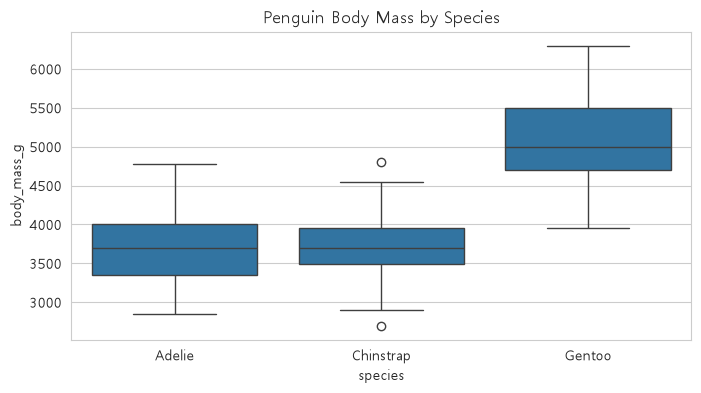


[Tukey HSD — 어느 쌍이 다른가]
     Multiple Comparison of Means - Tukey HSD, FWER=0.05      
  group1    group2  meandiff p-adj    lower     upper   reject
--------------------------------------------------------------
   Adelie Chinstrap   32.426 0.8807 -126.5002  191.3522  False
   Adelie    Gentoo 1375.354    0.0 1243.1786 1507.5294   True
Chinstrap    Gentoo 1342.928    0.0  1178.481  1507.375   True
--------------------------------------------------------------


In [44]:
# [C17] 일원 ANOVA: 세 종의 체중이 다른가?
groups = [g["body_mass_g"].values for _, g in penguins.groupby("species")]  # 집단별로 묶어서 계산
F, p = stats.f_oneway(*groups)                                    # 일원 ANOVA — F = 집단 간 분산 / 집단 내 분산

grand = penguins["body_mass_g"].mean()
ss_b = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
ss_t = ((penguins["body_mass_g"] - grand) ** 2).sum()
eta2 = ss_b / ss_t
lev = stats.levene(*groups).pvalue                                # 등분산 검정 — p가 작으면 등분산 가정 위배

print(f"ANOVA: F={F:.1f}, p={p:.2e}, η²={eta2:.2f}  (체중 변동의 {eta2:.0%}를 '종'이 설명)")
print(f"등분산(Levene) p={lev:.3f} → {'등분산 위배! Welch ANOVA/비모수 고려' if lev<0.05 else '등분산 OK'}")

fig, ax = plt.subplots(figsize=(8, 4))                            # 그래프 하나를 그릴 도화지 준비
sns.boxplot(data=penguins, x="species", y="body_mass_g", ax=ax)   # 상자그림 — 중앙값·사분위·이상치를 한눈에
ax.set_title("Penguin Body Mass by Species"); plt.show()

print("\n[Tukey HSD — 어느 쌍이 다른가]")
print(pairwise_tukeyhsd(penguins["body_mass_g"], penguins["species"]))  # 사후검정: 어느 '쌍'이 다른지 (다중비교 보정 포함)

## 그림으로 · 종별 평균 ± 95% 신뢰구간

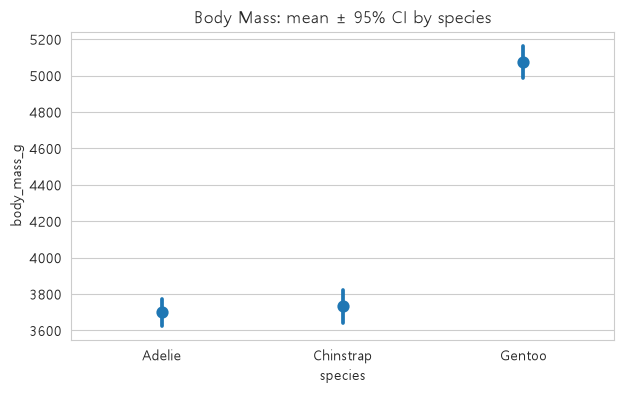

Adelie·Chinstrap의 구간은 겹치고, Gentoo는 멀찍이 떨어져 있습니다.


In [45]:
# [C18] [그림] 종별 평균 ± 95% 신뢰구간 — 구간이 겹치는가?
fig, ax = plt.subplots(figsize=(7, 4))                            # 그래프 하나를 그릴 도화지 준비
sns.pointplot(data=penguins, x="species", y="body_mass_g", errorbar=("ci", 95),  # 집단별 평균 ± 신뢰구간을 점으로
              linestyle="none", ax=ax)
ax.set_title("Body Mass: mean ± 95% CI by species"); plt.show()
print("Adelie·Chinstrap의 구간은 겹치고, Gentoo는 멀찍이 떨어져 있습니다.")

> **읽는 법(그림):** Adelie와 Chinstrap의 신뢰구간은 **겹치고**, Gentoo만 위로 한참 떨어져 있습니다. 구간이 겹치면 "차이가 있다고 보기 어렵다"는 시각 신호 — Tukey 결과(Adelie≈Chinstrap)와 정확히 일치합니다.

> 📌 **다른 산업에서는?** 일원 ANOVA는 매장 3곳 매출 비교, 약물 3종 효과 비교, 공정 조건 여러 개 비교 등 *3집단 이상*을 한 번에 검정할 때 쓰고, Tukey로 _어느 쌍이_ 다른지 짚습니다.

## 그림으로 · Tukey HSD 비교 구간

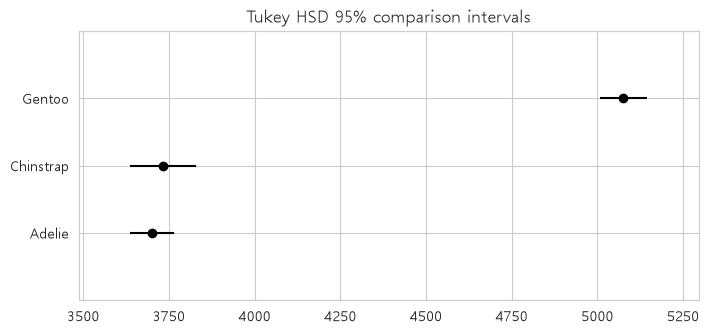

In [46]:
# [C19] [그림] Tukey HSD — 신뢰구간이 겹치지 않으면 유의 차이
tuk = pairwise_tukeyhsd(penguins["body_mass_g"], penguins["species"])  # 사후검정: 어느 '쌍'이 다른지 (다중비교 보정 포함)
tuk.plot_simultaneous(figsize=(8, 3.5))
plt.title("Tukey HSD 95% comparison intervals"); plt.show()

> **읽는 법(그림):** 각 종의 비교 구간이 _겹치면_ 차이가 유의하지 않다는 뜻입니다. Adelie·Chinstrap은 겹치고 Gentoo만 분리돼 — "Gentoo가 유독 무겁다"가 그림으로도 확인됩니다.

> **읽는 법:** F가 매우 크고 p≈0 — "종에 따라 체중이 다르다"가 강하게 지지됩니다(η²=0.67, 즉 체중 변동의 약 2/3가 종으로 설명!). 이건 앞서 *종별로 나누니 단봉*이던 발견과 정확히 맞물립니다.
>
> **그런데 Tukey를 보면** — Adelie와 Chinstrap은 _차이가 없고_(p-adj 큼), **둘 다 Gentoo와는 큰 차이**(약 1,350g)입니다. 즉 "Gentoo가 유독 무겁다"가 진실입니다. ANOVA만 보고 "셋 다 서로 다르다"고 하면 틀립니다.
>
> 또 등분산(Levene)이 깨졌으니(p<0.05), 엄밀히는 **Welch ANOVA**나 비모수 대안을 함께 고려합니다 — 그 *대안 도구*가 다음 시간입니다.

> ⚠️ **흔한 오해 / 함정**
> ❗ **"ANOVA가 유의하다 = 모든 집단이 서로 다르다" — 아닙니다.** ANOVA는 "어딘가 다르다"만 말합니다. _어느 쌍이_ 다른지는 반드시 **Tukey** 같은 사후검정으로 확인하세요(여기선 Adelie≈Chinstrap).

## 왜 t-test를 여러 번 하면 안 될까 — 다중비교 문제

집단이 3개(A·B·C)면 "A vs B, A vs C, B vs C"로 t-test를 **세 번** 하면 될 것 같습니다. 하지만 위험합니다.

검정을 한 번 할 때마다 1종 오류(차이가 없는데 있다고 잘못 판정)를 $\alpha = 5\%$ 감수합니다. 검정을 여러 번 하면 이 오류가 **누적**됩니다.

$$P(\text{한 번이라도 잘못 판정}) = 1 - (1-\alpha)^k$$

여기서 $k$는 검정 횟수입니다. $k=3$이면 약 14%, $k=10$이면 약 40%까지 치솟습니다 — "어딘가는 유의하다"가 거의 우연히 나오는 셈입니다.

> 💡 **그래서 ANOVA입니다.** 먼저 ANOVA로 "**전체에 차이가 있는가**"를 _한 번에_ 검정해 1종 오류율을 보존하고, 유의할 때만 **Tukey HSD**처럼 다중비교를 _보정한_ 사후검정으로 "_어느 쌍이_ 다른지"를 짚습니다.

In [47]:
# [C20] [확인] 검정을 반복할수록 1종 오류가 누적된다
alpha = 0.05
print("검정 횟수 k | 한 번이라도 잘못 판정할 확률 (FWER)")
print("-" * 44)
for k in [1, 3, 5, 10, 20]:
    fwer = 1 - (1 - alpha) ** k
    print(f"   k = {k:>2}   |        {fwer:6.1%}")
print()
print("→ k가 커질수록 '우연한 유의'가 급증합니다. ANOVA가 이를 한 번의 검정으로 막아줍니다.")

검정 횟수 k | 한 번이라도 잘못 판정할 확률 (FWER)
--------------------------------------------
   k =  1   |          5.0%
   k =  3   |         14.3%
   k =  5   |         22.6%
   k = 10   |         40.1%
   k = 20   |         64.2%

→ k가 커질수록 '우연한 유의'가 급증합니다. ANOVA가 이를 한 번의 검정으로 막아줍니다.


## ⌨️ 백문이 불여일타! (4) — 지느러미 길이 종별 ANOVA

```
[문제]
1) (따라하기) flipper_length_mm(지느러미 길이)를 종별로 ANOVA 해보세요. (결측은 dropna)
2) (해석) F·p·η²를 보고하고, Tukey로 어느 쌍이 다른지 확인해보세요.
3) (생각해보기) 등분산이 깨졌을 때 어떤 대안이 있을까요?
```

           count    mean   std
species                       
Adelie       151  189.95  6.54
Chinstrap     68  195.82  7.13
Gentoo       123  217.19  6.48

ANOVA: F = 594.8, p = 1.35e-111, η² = 0.78  (지느러미 길이 변동의 78%를 '종'이 설명)
등분산(Levene) p = 0.719 → 등분산 OK


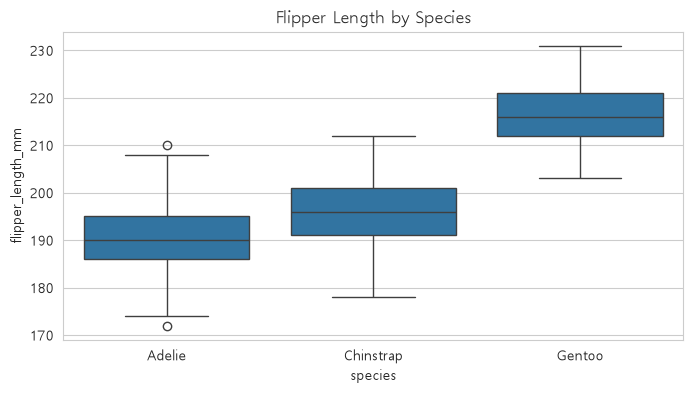


[Tukey HSD — 어느 쌍이 다른가]
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1    group2  meandiff p-adj  lower   upper  reject
---------------------------------------------------------
   Adelie Chinstrap   5.8699   0.0  3.5866  8.1532   True
   Adelie    Gentoo  27.2333   0.0 25.3344 29.1323   True
Chinstrap    Gentoo  21.3635   0.0 19.0008 23.7261   True
---------------------------------------------------------


In [49]:
# [C21] ⌨️ 백문이 불여일타! (4) — 지느러미 길이 종별 ANOVA와 Tukey

# 1) 결측 제거 후 종별 ANOVA
pf = penguins.dropna(subset=["flipper_length_mm"])
groups_f = [g["flipper_length_mm"].values for _, g in pf.groupby("species")]

print(pf.groupby("species")["flipper_length_mm"].agg(["count", "mean", "std"]).round(2))

F_f, p_f = stats.f_oneway(*groups_f)

# 2) 효과 크기 η² = 집단 간 제곱합 / 전체 제곱합
grand_f = pf["flipper_length_mm"].mean()
ss_b = sum(len(g) * (g.mean() - grand_f) ** 2 for g in groups_f)
ss_t = ((pf["flipper_length_mm"] - grand_f) ** 2).sum()
eta2_f = ss_b / ss_t

lev_f = stats.levene(*groups_f).pvalue

print(f"\nANOVA: F = {F_f:.1f}, p = {p_f:.2e}, η² = {eta2_f:.2f}  (지느러미 길이 변동의 {eta2_f:.0%}를 '종'이 설명)")
print(f"등분산(Levene) p = {lev_f:.3f} → {'등분산 위배! Welch ANOVA/비모수 고려' if lev_f < 0.05 else '등분산 OK'}")

# 상자그림
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=pf, x="species", y="flipper_length_mm", ax=ax)
ax.set_title("Flipper Length by Species"); plt.show()

# Tukey HSD — 어느 쌍이 다른가
print("\n[Tukey HSD — 어느 쌍이 다른가]")
print(pairwise_tukeyhsd(pf["flipper_length_mm"], pf["species"]))

# 2) 해석:
#    F ≈ 594.8, p ≈ 1.4e-111로 매우 작아 '세 종의 평균 지느러미 길이가 모두 같다'는 H0를 기각한다.
#    η² ≈ 0.78 → 지느러미 길이 변동의 약 78%를 종이 설명할 만큼 효과가 매우 크다.
#    Tukey 결과 세 쌍(Adelie-Chinstrap, Adelie-Gentoo, Chinstrap-Gentoo) 모두 유의하게 다르다.
#    (Adelie 약 190mm < Chinstrap 약 196mm < Gentoo 약 217mm)
#    체중 ANOVA에서는 Adelie≈Chinstrap이었지만, 지느러미 길이는 세 종이 모두 구분된다.
#
# 3) 생각해보기 — 등분산이 깨졌을 때의 대안:
#    - Welch ANOVA: 집단별 분산이 달라도 쓸 수 있는 ANOVA (예: pingouin.welch_anova)
#      → 사후검정은 Games-Howell (pingouin.pairwise_gameshowell)
#    - Kruskal-Wallis 검정: 정규성·등분산 가정이 필요 없는 비모수 검정 (stats.kruskal)
#      → 평균이 아니라 '순위(중앙값 위치)'를 비교한다.
#    (이번 데이터는 Levene p ≈ 0.72로 등분산이 성립하므로 일반 ANOVA로 충분하다.)

<details>
<summary>(클릭) 💡 힌트</summary>

- 먼저 `dropna(subset=["flipper_length_mm"])`로 결측을 제거한 뒤, `groupby("species")`로 종별 값 배열의 리스트를 만들어보세요.
- [C17]에서 본 흐름 그대로입니다 — `stats.f_oneway(*그룹들)`로 F·p를 구하고, `pairwise_tukeyhsd(값, 라벨)`로 어느 쌍이 다른지 확인해보세요.
- 3)번은 [C17] 출력의 등분산(Levene) 경고 문구를 떠올려보세요 — Welch ANOVA나 비모수 검정이 후보입니다.

</details>

## 🚦 짚고 넘어가기 — Part 6 ANOVA와 Tukey

1. 집단이 셋 이상일 때 t-test를 반복하면 왜 위험한가요?
2. F 통계량의 분자·분모는 무엇을 비교하나요?
3. ANOVA 다음에 Tukey가 _왜_ 필요한가요?

> 💡 **다음 Part 예고:** 지금까지 "유의한가?"(p)만 봤습니다. 하지만 **표본이 크면 사소한 차이도 유의**해집니다. "유의"와 "중요"는 다릅니다 — 그 간극을 메우는 **효과 크기와 신뢰구간**이 마지막 Part입니다.

---

# Part 7. p-value 너머 — 효과 크기와 신뢰구간

p-value에는 **함정**이 있습니다. 표본이 아주 크면 *실무적으로 무의미한 작은 차이*도 "유의"하게 나옵니다. "유의하다(Statistically Significant)"가 곧 "중요하다(Practically Important)"는 아닙니다.

> ❓ **이 파트에서 답할 질문:** "유의하다"는 판정만으로 충분할까? 차이가 _얼마나 큰지_, *어디쯤인지*는 어떻게 말할까?

## 💡 쉽게 말하면 — p·효과 크기·신뢰구간은 다른 질문

```
p-value     : "우연일까?"          (있다/없다)         ← 표본 크기에 민감
효과 크기    : "차이가 얼마나 큰가?"  (작다/중간/크다)    ← 표본 크기와 무관
신뢰구간(CI) : "차이가 어디쯤인가?"   (범위)             ← 불확실성을 보여줌
```

<img src="https://upload.wikimedia.org/wikipedia/commons/1/15/Cohens_d_4panel.svg" width="640" alt="Cohens d 4panel.svg">

Cohen's d가 커질수록 두 집단 분포가 멀어지는 모습. d=0.2는 거의 포개져 있고, d=2.0쯤 되면 두 집단이 거의 분리됩니다. **효과 크기는 '두 분포가 표준편차 몇 배만큼 떨어졌나'** 를 뜻합니다.

> 🖼️ **그림 출처** — Wikimedia Commons, `Cohens d 4panel.svg` (CC BY-SA 3.0) · 원본·라이선스 상세: https://commons.wikimedia.org/wiki/File:Cohens_d_4panel.svg

## 효과 크기와 신뢰구간

**Cohen's d** (두 집단 평균차의 표준화):

$$d = \frac{\bar{x}_1 - \bar{x}_2}{s_{\text{pooled}}}$$

- $s_{\text{pooled}}$: 두 집단을 합친 표준편차. 단위를 없애 *차이의 크기*만 남김.

| Cohen's d | 해석      |
| --------- | --------- |
| ≈ 0.2     | 작은 효과 |
| ≈ 0.5     | 중간 효과 |
| ≈ 0.8+    | 큰 효과   |

- **$\eta^2$**(ANOVA): 전체 변동 중 집단이 설명하는 비율(Part 6에서 0.67).
- **95% CI**: 평균차가 있을 법한 범위. 0을 포함하면 "차이 없음"과 양립.

> 💡 **결과 보고의 3종 세트(ASA 권고):** ① 점추정 ② 불확실성(CI) ③ 효과 크기 — _항상 셋을 함께_ 보고합니다. 이 모듈 전체를 관통하는 태도입니다.

## 예제 · 효과 크기 3종 세트로 보고하기

In [50]:
# [C22] 효과 크기 3종 세트 — tips 성별 차이를 '제대로' 보고하기
def cohens_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na-1)*a.std(ddof=1)**2 + (nb-1)*b.std(ddof=1)**2) / (na+nb-2))
    return (a.mean() - b.mean()) / sp

t, p = stats.ttest_ind(male, female, equal_var=False)             # 두 독립 집단의 평균 비교 (equal_var=False면 Welch)
diff = male.mean() - female.mean()
se = np.sqrt(male.var(ddof=1)/len(male) + female.var(ddof=1)/len(female))
df = se**4 / ((male.var(ddof=1)/len(male))**2/(len(male)-1) + (female.var(ddof=1)/len(female))**2/(len(female)-1))
lo, hi = diff - stats.t.ppf(0.975, df)*se, diff + stats.t.ppf(0.975, df)*se
d = cohens_d(male, female)
size = "작음" if abs(d) < 0.5 else ("중간" if abs(d) < 0.8 else "큼")

print("[남녀 결제 금액 차이 — 3종 세트 보고]")
print(f"  ① 점추정(평균차) : {diff:.2f} 달러")
print(f"  ② 95% 신뢰구간   : [{lo:.2f}, {hi:.2f}]")
print(f"  ③ 효과 크기(d)   : {d:.2f}  → {size} 효과")
print(f"  (참고: p = {p:.3f})")

[남녀 결제 금액 차이 — 3종 세트 보고]
  ① 점추정(평균차) : 2.69 달러
  ② 95% 신뢰구간   : [0.45, 4.92]
  ③ 효과 크기(d)   : 0.30  → 작음 효과
  (참고: p = 0.019)


## 그림으로 · 같은 '유의'라도 효과 크기는 천차만별

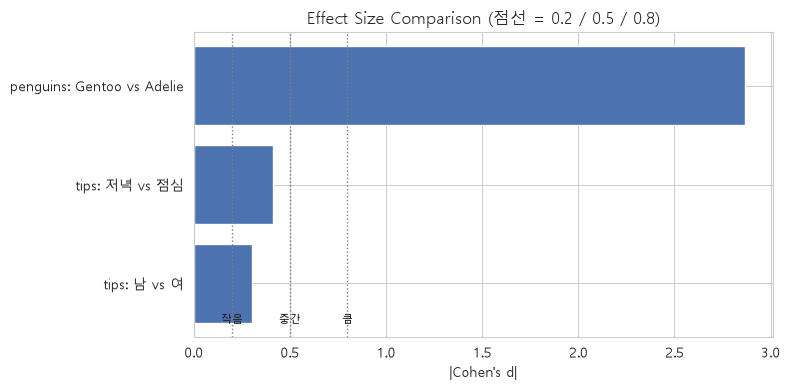

세 비교 모두 p<0.05(유의)지만, 효과 크기는 0.3에서 2+까지 — '유의'가 '중요'를 보장하지 않습니다.


In [51]:
# [C23] [그림] 효과 크기 비교 — 같은 '유의'라도 크기는 천차만별
comparisons = {
    "tips: 남 vs 여":            cohens_d(male, female),
    "tips: 저녁 vs 점심":        cohens_d(tips[tips.time=="Dinner"].total_bill, tips[tips.time=="Lunch"].total_bill),
    "penguins: Gentoo vs Adelie": cohens_d(penguins[penguins.species=="Gentoo"].body_mass_g,
                                           penguins[penguins.species=="Adelie"].body_mass_g),
}
fig, ax = plt.subplots(figsize=(8, 4))                            # 그래프 하나를 그릴 도화지 준비
ax.barh(list(comparisons), [abs(v) for v in comparisons.values()], color="#4C72B0")
for x, lab in [(0.2, "작음"), (0.5, "중간"), (0.8, "큼")]:
    ax.axvline(x, color="gray", ls=":", lw=1); ax.text(x, -0.4, lab, fontsize=8, ha="center")  # 세로 기준선 표시
ax.set_xlabel("|Cohen's d|"); ax.set_title("Effect Size Comparison (점선 = 0.2 / 0.5 / 0.8)")
plt.tight_layout(); plt.show()                                    # 그래프 간격 자동 정리 후 출력
print("세 비교 모두 p<0.05(유의)지만, 효과 크기는 0.3에서 2+까지 — '유의'가 '중요'를 보장하지 않습니다.")

> **읽는 법(그림):** 세 비교 모두 통계적으로 유의하지만, **효과 크기는 0.3(작음)에서 2 이상(매우 큼)까지** 천차만별입니다. p-value만 봤다면 셋 다 똑같이 "유의!"로 끝났겠지만, 효과 크기를 보면 _어디에 실제로 주목해야 하는지_ 가 드러납니다 — 이것이 ASA 권고의 실천입니다.

> 📌 **다른 산업에서는?** 효과 크기는 A/B 테스트(전환율 _상승폭_), 임상(치료 _효과 크기_), 교육(개입 _효과_)에서 "통계적 유의"를 넘어 _"비즈니스/임상적으로 의미 있는가"_ 를 판단하는 표준 지표입니다.

> **읽는 법:** 차이는 **통계적으로 유의**하지만(p<0.05), Cohen's d ≈ 0.30으로 **효과는 '작은' 수준**입니다. 즉 "남녀 차이가 _존재는_ 하지만, 프로모션 타깃을 가를 만큼 _크지는_ 않다"가 정직한 결론입니다. **p만 봤다면 '유의하니 타깃을 나누자'로 과잉 해석**했을 겁니다 — 이것이 ASA 권고의 핵심입니다.

> ⚠️ **흔한 오해 / 함정**
> ❗ **"p가 작다 = 효과가 크다" — 아닙니다.** p는 표본 크기에 민감해, 큰 표본에선 *사소한 차이*도 작은 p를 만듭니다. *차이의 크기*는 오직 **효과 크기**로 판단하세요.

## 효과 크기, 얼마면 "큰" 걸까 — 해석의 기준

효과 크기는 단위가 없어 서로 *비교*할 수 있습니다. 다만 "0.4가 큰 건가?"라는 감을 잡으려면 관습적 기준이 도움이 됩니다(절대 법칙은 아닙니다).

| 효과 크기                       | 작음 | 중간 | 큼   | 의미                                    |
| ------------------------------- | ---- | ---- | ---- | --------------------------------------- |
| **Cohen's d** (두 평균 차)      | 0.2  | 0.5  | 0.8  | 두 분포가 표준편차의 몇 배만큼 떨어졌나 |
| **$\eta^2$** (ANOVA, 설명 비율) | 0.01 | 0.06 | 0.14 | 전체 변동 중 집단이 설명하는 비율       |
| **상관계수 $r$**                | 0.1  | 0.3  | 0.5  | 두 변수의 선형 관계 강도                |

> ⚠️ **맥락이 기준보다 먼저입니다.** 의학에서 $d=0.2$는 수많은 생명을 좌우할 수 있고, 마케팅에서 $d=0.8$도 비용이 더 크면 무의미할 수 있습니다. 기준표는 *출발점*일 뿐, 최종 판단은 그 도메인의 **비용·편익**으로 합니다.

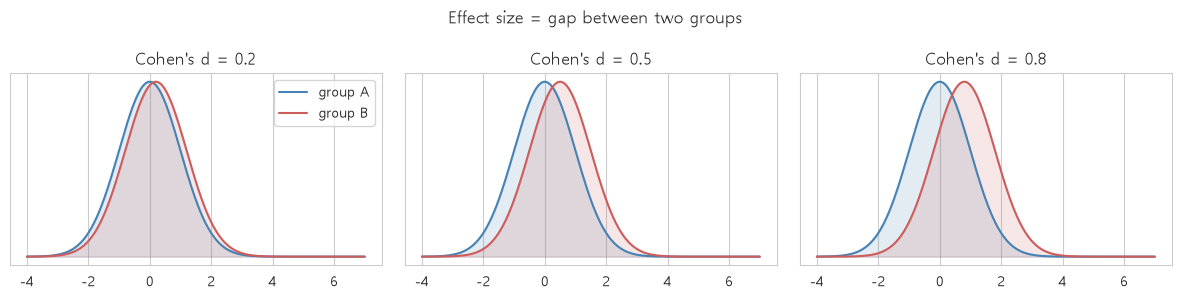

In [52]:
# [C24] [도식] Cohen's d 감 잡기 — d가 클수록 두 집단 분포가 멀어진다
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)      # 그림 한 장에 그래프 3개(1행 3열)
x = np.linspace(-4, 7, 400)                                       # 구간을 균등 간격으로 쪼갠 x축 값
for ax, d in zip(axes, [0.2, 0.5, 0.8]):
    ax.plot(x, stats.norm.pdf(x, 0, 1), color="steelblue")
    ax.plot(x, stats.norm.pdf(x, d, 1), color="indianred")
    ax.fill_between(x, stats.norm.pdf(x, 0, 1), alpha=0.15, color="steelblue")  # 곡선 아래 영역을 색으로 채움(= 면적은 확률)
    ax.fill_between(x, stats.norm.pdf(x, d, 1), alpha=0.15, color="indianred")  # 곡선 아래 영역을 색으로 채움(= 면적은 확률)
    ax.set_title(f"Cohen's d = {d}"); ax.set_yticks([])
axes[0].legend(["group A", "group B"])
plt.suptitle("Effect size = gap between two groups"); plt.tight_layout(); plt.show()  # 그래프 간격 자동 정리 후 출력

> **읽는 법(그림):** $d$가 0.2 → 0.8로 커질수록 두 분포(파랑·빨강)가 점점 떨어집니다. $d=0.2$는 거의 포개져 "있긴 한데 미미한" 차이, $d=0.8$은 눈에 띄게 분리된 "큰" 차이입니다. p-value만으론 이 *크기 감각*을 알 수 없습니다.

## p·효과크기·신뢰구간 — 세 질문, 세 도구

이 셋은 *서로 다른 질문*에 답합니다. 하나로 다른 둘을 대신할 수 없습니다.

| 도구                          | 답하는 질문                    | 한 줄 해석                           |
| ----------------------------- | ------------------------------ | ------------------------------------ |
| **p-value**                   | 차이가 _있는가?_ (존재)        | "우연이라 보기 어렵다"(작을 때)      |
| **효과 크기** ($d$, $\eta^2$) | 차이가 _얼마나 큰가?_ (크기)   | 표준편차·설명비율 기준의 크기 감각   |
| **신뢰구간** (CI)             | 그 크기가 _어디쯤인가?_ (범위) | 평균차의 그럴듯한 범위 + 불확실성 폭 |

> ⚠️ **신뢰구간, 흔히 틀리는 해석:** "95% CI [1.6, 6.0]"은 *"참값이 이 구간에 있을 확률이 95%"*라는 뜻이 **아닙니다**(참값은 고정된 한 점입니다). 정확히는 *"같은 방식으로 표본을 여러 번 뽑아 구간을 만들면, 그중 약 95%가 참값을 포함한다"*는 뜻입니다. 실무에선 **구간의 폭**(불확실성)과 **0(기준값) 포함 여부**(유의성)를 읽는 도구로 쓰면 충분합니다.

> 💡 표본이 커질수록 CI는 **좁아져** 더 정밀해집니다 — 그래서 "효과가 작아도 표본이 매우 크면 유의"가 나오죠(Part 4에서 본 그 현상입니다). p 하나에 휘둘리지 않으려면 _항상 세트로_ 보세요. 특히 비즈니스 보고에서는 "p가 작다"보다 _"효과가 중간 정도(d≈0.4)이고, 평균차는 대략 1~6달러 범위"_ 가 훨씬 행동으로 옮기기 쉬운 정보입니다.

## ⌨️ 백문이 불여일타! (5) — Gentoo vs Adelie Cohen's d

```
[문제]
1) (따라하기) Gentoo vs Adelie 체중의 Cohen's d를 구해보세요. (cohens_d 사용)
2) (해석) d 값을 작음/중간/큼으로 분류하고, Part 6의 Tukey 결과(1,350g 차이)와 연결해보세요.
3) (생각해보기) "유의하지만 효과가 작다"와 "유의하지 않지만 표본이 작다"는 각각 어떻게 보고해야 할까요?
```

In [54]:
# [C25] ⌨️ 백문이 불여일타! (5) — Gentoo vs Adelie 체중의 Cohen's d

# 1) 두 종의 체중 → Cohen's d ([C22]의 cohens_d 함수 사용)
gentoo = penguins[penguins["species"] == "Gentoo"]["body_mass_g"]
adelie = penguins[penguins["species"] == "Adelie"]["body_mass_g"]

d_ga = cohens_d(gentoo, adelie)
t_ga, p_ga = stats.ttest_ind(gentoo, adelie, equal_var=False)

# 2) 크기 분류 (0.2 작음 / 0.5 중간 / 0.8 큼)
if abs(d_ga) < 0.2:
    size = "매우 작음"
elif abs(d_ga) < 0.5:
    size = "작음"
elif abs(d_ga) < 0.8:
    size = "중간"
else:
    size = "큼"

print(f"Gentoo 평균 {gentoo.mean():.0f}g (n={len(gentoo)})  /  Adelie 평균 {adelie.mean():.0f}g (n={len(adelie)})")
print(f"평균 차이      : {gentoo.mean() - adelie.mean():.0f}g")
print(f"Cohen's d      : {d_ga:.2f}  → {size} 효과")
print(f"(참고) Welch t : t = {t_ga:.2f}, p = {p_ga:.2e}")

# 2) 해석:
#      '통계적으로는 유의하나 실질적 차이는 작다'고 명시한다. (표본이 매우 크면 작은 차이도 유의해진다)
#    - "유의하지 않지만 표본이 작다" → '차이가 없다'가 아니라 '차이가 있다는 증거가 부족하다'고 보고한다.
#      효과 크기와 넓은 신뢰구간을 함께 제시하고, 검정력이 부족했을 수 있으니 표본을 늘린 추가 조사를 제안한다.

Gentoo 평균 5076g (n=123)  /  Adelie 평균 3701g (n=151)
평균 차이      : 1375g
Cohen's d      : 2.87  → 큼 효과
(참고) Welch t : t = 23.39, p = 7.71e-65


<details>
<summary>(클릭) 💡 힌트</summary>

- `penguins`에서 종이 `"Gentoo"`인 행과 `"Adelie"`인 행의 `body_mass_g`를 각각 시리즈로 뽑아보세요.
- [C22]에서 정의한 `cohens_d(a, b)` 함수에 두 시리즈를 그대로 넣으면 됩니다.
- 분류 기준은 0.2/0.5/0.8(작음/중간/큼)입니다. 3)번 답은 주석으로 정리해보세요 — p와 효과 크기·표본 크기를 함께 언급하는 것이 핵심입니다.

</details>

## 🚦 짚고 넘어가기 — Part 7 효과 크기와 신뢰구간

1. "통계적으로 유의"와 "실무적으로 중요"는 왜 다른가요?
2. 3종 세트(점추정·CI·효과 크기)를 각각 한 문장으로?
3. 큰 표본에서 p-value를 _단독으로_ 믿으면 안 되는 이유는?

---

# 🧪 종합 실습 — 집단 차이 검정 보고서

오늘 배운 도구(가설검정·t-test·ANOVA·효과 크기)를 모아, 의사결정에 바로 쓸 **검정 보고서**를 만듭니다.

```
[1] 질문·가설 → [2] 적합한 검정 선택 → [3] 검정 수행 → [4] 3종 세트(점추정·CI·효과크기) → [5] 의사결정 번역
```

## 시나리오 1·2 — 두 집단 비교 (tips)

결제 금액을 **성별**과 **시간(점심/저녁)**으로 비교해, 검정 결과를 한 표로 모읍니다.

## 예제 · 2표본 비교 자동 요약표

In [53]:
# [C26] 시나리오 1·2 — 2표본 비교 자동 요약
def compare_two(df, value, group, a, b):
    x = df[df[group] == a][value].dropna()                        # 결측(NaN) 제거
    y = df[df[group] == b][value].dropna()                        # 결측(NaN) 제거
    t, p = stats.ttest_ind(x, y, equal_var=False)                 # 두 독립 집단의 평균 비교 (equal_var=False면 Welch)
    return {"비교": f"{a} vs {b}", "평균차": round(x.mean() - y.mean(), 2),
            "t": round(t, 2), "p": round(p, 4), "Cohen's d": round(cohens_d(x, y), 2),
            "판정": "유의" if p < 0.05 else "유의 아님"}

report = pd.DataFrame([
    compare_two(tips, "total_bill", "sex",  "Male",   "Female"),
    compare_two(tips, "total_bill", "time", "Dinner", "Lunch"),
])
report

,비교,평균차,t,p,Cohen's d,판정
0,Male vs Female,2.69,2.37,0.0186,0.30,유의
1,Dinner vs Lunch,3.63,3.12,0.0022,0.41,유의


> **읽는 법:** 둘 다 유의하지만, 효과 크기로 보면 _시간(저녁-점심)_ 쪽이 성별보다 큽니다. "언제 오느냐"가 "누구냐"보다 결제 금액을 더 가른다는 실무 인사이트입니다.

## 그림으로 · 평균차 ± 95% CI (forest plot)

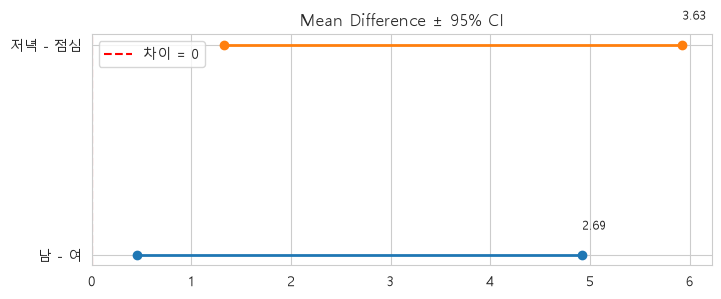

In [55]:
# [C27] [그림] 두 비교의 평균차 ± 95% CI (forest plot) — 0을 넘으면 유의
def diff_ci(x, y):
    d = x.mean() - y.mean()
    se = np.sqrt(x.var(ddof=1)/len(x) + y.var(ddof=1)/len(y))
    df = se**4 / ((x.var(ddof=1)/len(x))**2/(len(x)-1) + (y.var(ddof=1)/len(y))**2/(len(y)-1))
    h = stats.t.ppf(0.975, df) * se
    return d, d - h, d + h

rows = [("남 - 여", *diff_ci(male, female)),
        ("저녁 - 점심", *diff_ci(tips[tips.time == "Dinner"].total_bill, tips[tips.time == "Lunch"].total_bill))]
fig, ax = plt.subplots(figsize=(8, 3))                            # 그래프 하나를 그릴 도화지 준비
for i, (lab, d, lo, hi) in enumerate(rows):
    ax.plot([lo, hi], [i, i], "o-", lw=2)
    ax.text(hi, i + 0.12, f"{d:.2f}", fontsize=9)
ax.axvline(0, color="red", ls="--", label="차이 = 0")               # 세로 기준선 표시
ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows]); ax.set_xlim(left=0)
ax.set_title("Mean Difference ± 95% CI"); ax.legend(); plt.show()

> **읽는 법(그림):** 두 신뢰구간 모두 **0을 포함하지 않아** 유의합니다(구간이 0을 가로지르면 "차이 없음"과 양립). 구간의 _위치_(평균차)와 _폭_(불확실성)을 한눈에 보여주는 게 forest plot의 힘입니다.

## 시나리오 3 — 여러 집단 비교 (penguins ANOVA)

세 종의 체중을 ANOVA + Tukey로 한 번에 비교합니다(Part 6 재사용).

In [56]:
# [C28] 시나리오 3 — ANOVA 요약
groups = [g["body_mass_g"].values for _, g in penguins.groupby("species")]  # 집단별로 묶어서 계산
F, p = stats.f_oneway(*groups)                                    # 일원 ANOVA — F = 집단 간 분산 / 집단 내 분산
grand = penguins["body_mass_g"].mean()
eta2 = sum(len(g)*(g.mean()-grand)**2 for g in groups) / ((penguins["body_mass_g"]-grand)**2).sum()
print(f"종별 체중 ANOVA: F={F:.1f}, p={p:.2e}, η²={eta2:.2f}")
print("Tukey 요약: Adelie≈Chinstrap, 둘 다 Gentoo와 유의하게 다름 (Gentoo가 무겁다)")

종별 체중 ANOVA: F=343.6, p=2.89e-82, η²=0.67
Tukey 요약: Adelie≈Chinstrap, 둘 다 Gentoo와 유의하게 다름 (Gentoo가 무겁다)


## 시나리오 4 — 같은 기업의 전후 비교 (jtrain, 대응표본)

같은 기업의 1987 → 1988 불량률 변화를 **대응표본 t-test**와 3종 세트로 보고합니다. 여기서는 *짝지어진 차이*가 분석 단위입니다.

In [57]:
# [C28b] 시나리오 4 — 대응표본 3종 세트
diff = after - before
n = len(diff)
se_d = diff.std(ddof=1) / np.sqrt(n)
lo_d, hi_d = diff.mean() - stats.t.ppf(0.975, n - 1) * se_d, diff.mean() + stats.t.ppf(0.975, n - 1) * se_d
d_paired = diff.mean() / diff.std(ddof=1)          # 대응표본용 Cohen's d (차이 / 차이의 표준편차)
t3, p3 = stats.ttest_rel(after, before)                           # 대응표본 t-test = '차이'에 대한 1표본 t-test

print("[불량률 1987 → 1988 (같은 기업 %d곳)]" % n)
print(f"  ① 점추정(평균 변화) : {diff.mean():+.2f} %p")
print(f"  ② 95% 신뢰구간      : [{lo_d:+.2f}, {hi_d:+.2f}] %p")
print(f"  ③ 효과 크기(d)      : {d_paired:.2f}")
print(f"  (참고: t({n-1}) = {t3:.2f}, p = {p3:.4f})")

# 정규성이 의심되면? 차이의 분포를 확인하고, 비모수 대안도 함께 (다음 시간 예고)
print(f"\n  차이의 정규성(Shapiro) p = {stats.shapiro(diff).pvalue:.2e}  → 정규 가정이 약함")  # 정규성 검정 — H0: 정규분포를 따른다
print(f"  비모수 대안 Wilcoxon 부호순위 p = {stats.wilcoxon(before, after).pvalue:.4f}  (D014에서 배웁니다)")  # Wilcoxon 부호순위 — 대응표본 t-test의 비모수 짝꿍

[불량률 1987 → 1988 (같은 기업 54곳)]
  ① 점추정(평균 변화) : -0.82 %p
  ② 95% 신뢰구간      : [-1.48, -0.17] %p
  ③ 효과 크기(d)      : -0.34
  (참고: t(53) = -2.52, p = 0.0147)

  차이의 정규성(Shapiro) p = 2.20e-08  → 정규 가정이 약함
  비모수 대안 Wilcoxon 부호순위 p = 0.0029  (D014에서 배웁니다)


> **읽는 법:** 평균 변화는 음수(불량률 감소)이고 신뢰구간이 0을 포함하지 않아 "유의한 감소"입니다. 그런데 **차이의 정규성 검정이 기각**됩니다 — 불량률처럼 강하게 치우친 변수에서 흔한 일입니다. 그래서 순위 기반의 **Wilcoxon 부호순위 검정**을 함께 돌려 같은 결론이 나오는지 확인했습니다(둘 다 유의 → 결론이 가정에 의존하지 않는다는 뜻이라 더 든든합니다).
>
> ⚠️ 다시 강조하면, 이것은 "감소했다"까지의 진술입니다. *무엇이 그 감소를 만들었나*(훈련 보조금? 경기? 학습효과?)는 D017의 준실험 설계가 필요한 질문입니다.

## 시나리오 5 — 실제 무작위 실험의 ANOVA (Project STAR)

마지막으로 **진짜 실험 데이터**를 봅니다. Project STAR는 학생을 세 가지 학급 유형에 *무작위로 배정*했습니다 — `small.class`(소규모), `regular`(일반), `regular.with.aide`(일반+보조교사). 학급 유형에 따라 유치원 수학 점수가 다를까요?

무작위 배정이라는 점이 중요합니다. 관찰 데이터라면 "원래 잘하는 학생이 소규모 학급에 갔을 수도"라는 의심이 남지만, 무작위 배정이면 그 걱정이 크게 줄어듭니다.

In [58]:
# [C28c] 시나리오 5 — Project STAR: 학급 유형 3집단 ANOVA + Tukey
groups_star = [g["tmathssk"].values for _, g in star.groupby("classk")]  # 집단별로 묶어서 계산
F_s, p_s = stats.f_oneway(*groups_star)                           # 일원 ANOVA — F = 집단 간 분산 / 집단 내 분산
grand_s = star["tmathssk"].mean()
eta2_s = (sum(len(g) * (g.mean() - grand_s) ** 2 for g in groups_star)
          / ((star["tmathssk"] - grand_s) ** 2).sum())

print("[Project STAR — 유치원 수학 점수]")
print(star.groupby("classk")["tmathssk"].agg(["count", "mean", "std"]).round(2))  # 집단별로 묶어서 계산
print(f"\nANOVA: F({len(groups_star)-1}, {len(star)-len(groups_star)}) = {F_s:.2f}, "
      f"p = {p_s:.2e}, η² = {eta2_s:.4f}")
print(f"등분산(Levene) p = {stats.levene(*groups_star).pvalue:.3f}")  # 등분산 검정 — p가 작으면 등분산 가정 위배

print("\n[Tukey HSD — 어느 쌍이 다른가]")
print(pairwise_tukeyhsd(star["tmathssk"], star["classk"]))        # 사후검정: 어느 '쌍'이 다른지 (다중비교 보정 포함)

[Project STAR — 유치원 수학 점수]
                   count    mean    std
classk                                 
regular             2000  483.26  47.50
regular.with.aide   2015  483.01  46.11
small.class         1733  491.47  49.47

ANOVA: F(2, 5745) = 18.55, p = 9.30e-09, η² = 0.0064
등분산(Levene) p = 0.001

[Tukey HSD — 어느 쌍이 다른가]
           Multiple Comparison of Means - Tukey HSD, FWER=0.05            
      group1            group2      meandiff p-adj   lower   upper  reject
--------------------------------------------------------------------------
          regular regular.with.aide  -0.2511 0.9847 -3.7752  3.2731  False
          regular       small.class   8.2093    0.0  4.5451 11.8735   True
regular.with.aide       small.class   8.4604    0.0  4.8025 12.1182   True
--------------------------------------------------------------------------


> **읽는 법:** ANOVA의 p가 매우 작아 "학급 유형에 따라 점수가 다르다"가 지지됩니다. Tukey를 보면 **소규모 학급만 나머지 둘보다 유의하게 높고, `regular`와 `regular.with.aide`는 차이가 없습니다**(보조교사를 붙이는 것만으로는 효과가 없었다는 뜻). ANOVA만 보고 "세 유형이 다 다르다"고 했다면 틀렸을 겁니다.
>
> 그런데 **η²가 0.01 내외**입니다 — 점수 변동의 1% 정도만 학급 유형으로 설명됩니다. "통계적으로는 확실히 유의, 효과 크기는 작음"의 교과서적 사례입니다(표본이 5,700명이라 작은 차이도 잡힙니다). 그래서 정책 판단은 이 효과 크기와 *학급 축소 비용*을 함께 놓고 해야 합니다 — p 하나로 "소규모 학급을 전면 도입"이라 결론 내릴 수 없습니다.
>
> ⚠️ **가정 점검도 잊지 마세요.** 출력의 Levene 검정 p가 0.05보다 작아 **등분산 가정이 깨졌습니다**(집단마다 점수의 퍼짐이 다름). 표본이 크고 집단 크기도 비슷해 일원 ANOVA가 크게 왜곡되지는 않지만, 엄밀히는 **Welch ANOVA**(`pingouin.welch_anova`)나 비모수 **Kruskal-Wallis**(D014)로 결론이 바뀌지 않는지 확인하는 것이 정석입니다.
>
> 💡 **연결:** 무작위 배정 덕분에 이 차이를 "학급 유형의 효과"로 해석할 여지가 커집니다. 그 논리를 정면으로 다루는 것이 **D016(A/B 테스트·인과추론)** 입니다.

## 📋 집단 차이 검정 보고서 + 후속 전략

# 집단 차이 검정 보고서

## 1. 질문과 데이터

- tips: 결제 금액(total_bill)이 **성별**·**시간대**에 따라 다른가? (Welch 2표본 t-test)
- penguins: 체중(body_mass_g)이 **종**에 따라 다른가? (일원 ANOVA + Tukey)

## 2. 결과 요약 (3종 세트)

| 비교            | 평균차  | 95% CI        | 효과크기          | p       | 판정                          |
| --------------- | ------- | ------------- | ----------------- | ------- | ----------------------------- |
| 성별(남-여)     | 2.69$   | [0.45, 4.92]  | d=0.30 (작음)     | 0.019   | 유의                          |
| 시간(저녁-점심) | 3.63$   | [1.33, 5.93]  | d=0.41 (작음)     | 0.002   | 유의                          |
| 종(ANOVA)       | —       | —             | η²=0.67 (큼)      | 2.9e-82 | 유의(Gentoo가 다름)           |

- **성별:** p<0.05로 유의하지만, d=0.30으로 효과가 작고 CI 하한이 0.45달러로 0에 가깝다 → 차이가 실질적으로 작을 수 있다.
- **시간대:** p=0.002로 유의하고, d=0.41로 성별보다 효과가 크다(여전히 '작음' 범위). CI 전체가 1달러 이상이다.
- **종:** η²=0.67로 체중 변동의 약 67%를 종이 설명한다. Tukey 결과 Adelie≈Chinstrap이며, Gentoo가 두 종보다 약 1,350g 무겁다(d≈2.87).

## 3. 의사결정 제안

- **성별 차이는 유의하나 효과가 작아** 타깃 분리 근거로는 약함 → 보류
  - 이유: d=0.30, CI 하한이 0.45달러 → 실제  .
- **시간대 차이는 효과가 더 큼** → **저녁 프로모션** 우선 검토
  - 이유: 평균 3.6달러 차이, CI 전체가 양수(1다만 효과는 '작음~중간' 수준이므로 A/B 테스트로 효과를 검증한 뒤 확대한다.
- **(가정 점검)** penguins는 등분산이 깨져(Le 수로 재확인했다.
  - Welch ANOVA: F(2, 189.5)=317.6, p≈3.1e-61 / Kruskal-Wallis: H=217.6, p≈5.6e-48 → **결론 동일(유의)**

제가 직접 돌려본 결과로 채운 값:
- 성별: 평균차 2.69달러, CI [0.45, 4.92], d=0.30, p=0.019
- 시간대: 평균차 3.63달러, CI [1.33, 5.93], d
- 종(ANOVA): F=343.6, p≈2.9×10⁻⁸², η²=0.67
- 등분산(Levene): p=0.006으로 위배돼요. 그래서 Welch ANOVA와 Kruskal-Wallis로 다시 확인했고, 결론은 그대로 유의해요.

## 결과를 제대로 보고하는 법 — 표준 표기와 흔한 실수

분석을 잘해도 *보고*가 엉성하면 의사결정으로 이어지지 못합니다. 통계 결과는 아래 **표준 형식**으로 적습니다(학계·실무 공통).

| 검정            | 표준 보고 형식 (예)                                                                                     |
| --------------- | ------------------------------------------------------------------------------------------------------- |
| 2표본 t-test    | 남성이 여성보다 결제액이 높았다, `t(199.8) = 2.37, p = .019, Cohen's d = 0.30`(작음), `95% CI [0.45, 4.92]` |
| 대응표본 t-test | 같은 기업의 불량률이 감소했다, `t(53) = -2.52, p = .015, d = -0.34`(작음~중간)                            |
| 일원 ANOVA      | 종에 따라 체중이 달랐다, `F(2, 339) = 343.6, p < .001, η² = 0.67`(큼)                                     |

*위 숫자는 이 노트북의 [C22]·[C28b]·[C17] 출력에서 그대로 가져온 값입니다. 여러분의 보고서에는 **반드시 자기 분석 출력의 숫자**를 넣으세요.*

핵심은 **세 가지를 함께** 적는 것입니다.

1. **방향·결론** — "무엇이 무엇보다 어떻다"를 _먼저_ (숫자보다 말이 앞섭니다)
2. **검정통계량과 자유도** — `t(df)`, `F(df1, df2)`
3. **p · 효과크기 · 신뢰구간** — 유의성(p) + 크기(d·η²) + 범위(CI)를 _세트로_

> 💡 **자유도가 소수인 이유:** Welch t-test는 두 집단의 분산이 다를 수 있다고 보고 자유도를 *보정*하기 때문에 `t(199.8)`처럼 소수가 나옵니다. 등분산을 가정하는 Student t라면 `t(242)`처럼 정수가 됩니다. 어느 쪽을 썼는지 밝히는 것도 보고의 일부입니다.

> 📌 **흔한 실수 5가지 (제출 전 체크):**
>
> 1. p만 보고하고 **효과 크기·CI를 빼먹는다** → "유의하지만 사소한" 결과를 놓칩니다
> 2. "p ≥ 0.05"를 **"차이가 없다"로 단정** → "증거가 부족하다"가 정확한 표현입니다
> 3. **자유도(df)를 빠뜨린다** → 재현·검증이 어려워집니다
> 4. 3집단 이상에 **t-test를 반복** → 다중비교로 1종 오류가 누적됩니다(ANOVA를 쓰세요)
> 5. **가정 점검 없이** 검정부터 → 정규성·등분산이 깨졌는지 먼저 확인합니다

> ✏️ **나쁜 보고 → 좋은 보고**
>
> - ✗ "성별에 따라 결제액이 유의하게 달랐다(p < 0.05)."
> - ✓ "남성의 평균 결제액이 여성보다 약 2.7달러 높았다(`t(199.8) = 2.37, p = .019, d = 0.30, 95% CI [0.45, 4.92]`). 다만 효과 크기가 작고 신뢰구간의 아래쪽이 0.45달러에 불과해, 단독으로 타깃을 분리하는 근거로는 약하다."

> 💡 **한 문장 원칙:** _방향을 말로 먼저, 숫자는 괄호로 뒤에, 그리고 p·효과크기·CI는 항상 세트로._

## 검정을 고르기 전에 — 가정 점검 (정규성·등분산)

검정 선택의 갈림길은 **정규성**과 **등분산**입니다. 눈(그림)과 숫자(검정), 둘 다로 확인합니다.

- **정규성:** Q-Q plot(눈) + **Shapiro-Wilk 검정**(숫자). $H_0$ = "정규분포를 따른다" → p가 크면 정규성 _유지_.
- **등분산:** **Levene 검정**. $H_0$ = "두 집단 분산이 같다" → p가 크면 등분산 _유지_.

> ⚠️ **가정 검정의 역설:** 표본이 매우 크면 사소한 비정규성·이분산도 "유의"하게 나옵니다. 그래서 **그림(Q-Q·분포)으로 먼저 보고**, 검정은 보조로 씁니다. "p < 0.05니까 무조건 비모수"가 아니라 *정도*를 함께 봐요.

In [ ]:
# [C29] [확인] 가정 점검 — 정규성(Shapiro-Wilk)·등분산(Levene)
m = tips[tips["sex"] == "Male"]["total_bill"]
f = tips[tips["sex"] == "Female"]["total_bill"]

sw_m = stats.shapiro(m); sw_f = stats.shapiro(f)                  # 정규성 검정 — H0: 정규분포를 따른다
lev  = stats.levene(m, f)                                         # 등분산 검정 — p가 작으면 등분산 가정 위배
print("[정규성 — Shapiro-Wilk]  H0: 정규분포를 따른다")
print(f"  남성 결제액 : p = {sw_m.pvalue:.4f}")
print(f"  여성 결제액 : p = {sw_f.pvalue:.4f}")
print("\n[등분산 — Levene]  H0: 두 집단 분산이 같다")
print(f"  남성 vs 여성 : p = {lev.pvalue:.4f}")
print("\n→ 정규성 p가 작으면(비정규) 비모수 검정을, 등분산 p가 작으면 Welch를 고려합니다.")

## 오늘의 검정 선택 지도 — 상황에 맞는 도구 고르기

오늘 배운 검정들을 _언제 쓰는지_ 한 장으로 정리합니다. 이 표가 "진단 → 행동(어떤 검정?)"을 잇는 다리입니다.

| 집단 수             | 짝지어졌나 | 정규성     | 권장 검정                        |
| ------------------- | ---------- | ---------- | -------------------------------- |
| 1개 (기준값과 비교) | —          | 만족       | 1표본 t-test                     |
| 2개                 | 독립       | 만족       | 2표본 t-test (분산 다르면 Welch) |
| 2개                 | 대응(짝)   | 만족       | 대응표본 t-test                  |
| 3개 이상            | 독립       | 만족       | 일원 ANOVA → (유의 시) Tukey HSD |
| 위 어느 경우든      | —          | **불만족** | 비모수 검정 — **다음 시간(D014)** |

```text
                    몇 집단을 비교하나?
              ┌───────────┼────────────┐
            1집단        2집단       3집단 이상
              │        ┌──┴──┐           │
          1표본 t    대응?  독립?      일원 ANOVA
                      │       │            │
                 대응표본 t  2표본 t   (유의) Tukey
```

> 💡 **다음 시간 복선:** 위 표의 마지막 줄(정규성 **불만족**)이 바로 **비모수 검정**입니다. 데이터가 정규분포를 따르지 않거나 순위·서열 자료일 때 쓰는 도구입니다.

In [ ]:
# [C30] [도구] 상황을 넣으면 적절한 검정을 추천하는 미니 가이드
def recommend_test(n_groups, paired=False, normal=True, equal_var=True):
    """집단 수·짝지음·정규성·등분산 → 권장 검정 이름"""
    if n_groups == 1:
        return "1표본 t-test" if normal else "Wilcoxon 부호순위 검정 (비모수)"
    if n_groups == 2:
        if paired:
            return "대응표본 t-test" if normal else "Wilcoxon 부호순위 검정 (비모수)"
        if not normal:
            return "Mann-Whitney U 검정 (비모수)"
        return "Student's t-test" if equal_var else "Welch's t-test"
    # 3집단 이상
    if not normal:
        return "Kruskal-Wallis 검정 (비모수) → 사후 Dunn"
    return "일원 ANOVA → 사후 Tukey HSD"

cases = [
    dict(n_groups=1, normal=True),
    dict(n_groups=2, paired=True,  normal=True),
    dict(n_groups=2, paired=False, normal=True, equal_var=False),
    dict(n_groups=2, paired=False, normal=False),
    dict(n_groups=3, paired=False, normal=True),
    dict(n_groups=3, paired=False, normal=False),
]
for c in cases:
    print(f"{str(c):<62} → {recommend_test(**c)}")

---

# ❓ 오늘의 퀴즈

배운 내용을 잠깐 확인해보겠습니다. 틀려도 괜찮습니다.

## 개념 퀴즈

1. $H_0$를 "기각"한다는 것은 무슨 뜻인가요?
2. 검정력(Power)을 높이는 방법 한 가지는?
3. 집단이 셋 이상일 때 t-test 대신 무엇을 쓰고, 그 다음 어느 쌍이 다른지는 무엇으로 확인하나요?
4. p-value와 효과 크기는 각각 어떤 질문에 답하나요?

## 해석 퀴즈 (옳고 그름 판별)

다음 보고 문장 중 **잘못된** 것을 모두 고르세요.

- (가) "p = 0.03이므로 두 집단은 확실히 다르고, 차이도 큽니다."
- (나) "p = 0.20이므로 두 집단은 차이가 없음이 증명되었습니다."
- (다) "ANOVA가 유의하므로 세 종이 모두 서로 다릅니다."
- (라) "차이는 유의하지만 Cohen's d=0.2로 작아, 실무 영향은 제한적입니다."

## 코드 퀴즈

`tips`에서 **흡연자(smoker=Yes) vs 비흡연자(No)** 의 결제 금액을 2표본 t-test로 비교하고, **3종 세트(평균차·p·Cohen's d)** 를 출력하세요.

In [59]:
# [C31] 코드 퀴즈 — 흡연자 vs 비흡연자 결제 금액 t-test와 3종 세트
smoker     = tips[tips["smoker"] == "Yes"]["total_bill"]
non_smoker = tips[tips["smoker"] == "No"]["total_bill"]
alpha = 0.05

# Welch 2표본 t-test (Levene p ≈ 0.045로 등분산이 의심되므로 Welch 사용)
res = stats.ttest_ind(smoker, non_smoker, equal_var=False)
t_s, p_s = res.statistic, res.pvalue

# ① 평균차 + 95% CI (Welch)
diff = smoker.mean() - non_smoker.mean()
va, vb = smoker.var(ddof=1) / len(smoker), non_smoker.var(ddof=1) / len(non_smoker)
se = np.sqrt(va + vb)
df_w = se**4 / (va**2 / (len(smoker) - 1) + vb**2 / (len(non_smoker) - 1))
lo, hi = diff - stats.t.ppf(0.975, df_w) * se, diff + stats.t.ppf(0.975, df_w) * se

# ③ 효과 크기 ([C22]의 cohens_d)
d_s = cohens_d(smoker, non_smoker)
size = "매우 작음" if abs(d_s) < 0.2 else ("작음" if abs(d_s) < 0.5 else ("중간" if abs(d_s) < 0.8 else "큼"))

print(f"흡연자 평균 {smoker.mean():.2f} (n={len(smoker)})  /  비흡연자 평균 {non_smoker.mean():.2f} (n={len(non_smoker)})")
print("[흡연자 vs 비흡연자 결제 금액 — 3종 세트]")
print(f"  ① 평균차        : {diff:.2f} 달러   (95% CI [{lo:.2f}, {hi:.2f}])")
print(f"  ② p-value       : {p_s:.3f}   → {'유의' if p_s < alpha else '유의하지 않음'}")
print(f"  ③ Cohen's d     : {d_s:.2f}   → {size} 효과")
print(f"  표준 표기: t({df_w:.1f}) = {t_s:.2f}, p = {p_s:.3f}, d = {d_s:.2f}, 95% CI [{lo:.2f}, {hi:.2f}]")

# 해석: 흡연자가 평균 약 1.57달러 더 결제했지만 p ≈ 0.20으로 유의하지 않고,
#       d ≈ 0.18로 효과도 매우 작다. 95% CI가 0을 포함한다([-0.84, 3.98]).
#       → "흡연 여부에 따른 결제 금액 차이의 증거가 부족하며, 있더라도 작을 것"으로 보고한다.
#         ('차이가 없다'고 단정하지 않는다.)

흡연자 평균 20.76 (n=93)  /  비흡연자 평균 19.19 (n=151)
[흡연자 vs 비흡연자 결제 금액 — 3종 세트]
  ① 평균차        : 1.57 달러   (95% CI [-0.84, 3.98])
  ② p-value       : 0.201   → 유의하지 않음
  ③ Cohen's d     : 0.18   → 매우 작음 효과
  표준 표기: t(169.6) = 1.28, p = 0.201, d = 0.18, 95% CI [-0.84, 3.98]


> **읽는 법:** 흡연 여부의 결제 금액 차이는 효과 크기가 작은 편입니다. _p만_ 보지 말고 _d_ 까지 보는 습관 — 이게 분석가의 정직함입니다.

---

# 🎓 오늘의 정리

## 오늘 배운 것이 어떻게 이어졌나

```
가설검정 6단계        판단의 절차 (H0를 의심한다)
   ↓
1·2종 오류·검정력      틀리는 두 방식 + 진짜를 잡는 힘
   ↓
t-test 3종            1표본·2표본·대응표본
   ↓
ANOVA + Tukey         여러 집단을 한 번에 (+ 어느 쌍이?)
   ↓
효과 크기·신뢰구간     p 너머 — 얼마나 큰가, 어디쯤인가 (3종 세트)
```

## 한 장 정리

| 도구            | 언제              | 핵심                              |
| --------------- | ----------------- | --------------------------------- |
| 2표본 t-test    | 독립 두 집단 평균 | `ttest_ind(..., equal_var=False)` |
| 대응표본 t-test | 같은 대상 전/후   | `ttest_rel`                       |
| 일원 ANOVA      | 세 집단 이상      | `f_oneway` → **Tukey**            |
| 효과 크기       | "얼마나 큰가"     | Cohen's d, $\eta^2$               |
| 3종 세트        | 보고 표준         | 점추정 · CI · 효과 크기           |

## 🎓 다음 시간 예고

> **"가정이 깨지면? 범주형이면? — 다른 도구로 갈아탄다."**
>
> 오늘 t-test·ANOVA는 _정규성·등분산_ 을 가정했습니다(펭귄에서 등분산이 깨졌습니다). 가정이 깨지거나, 데이터가 _범주형_(예: 클릭/구매 여부)이면 어떻게 할까요? 다음 시간엔 **카이제곱 검정**(범주형)과 **비모수 검정**(가정이 깨질 때), 그리고 **베이즈 정리**를 만납니다.

> 💡 **개념 누적 연결:** 오늘의 _효과 크기·신뢰구간_ 습관은 A/B 테스트로, *Gentoo가 다르다*는 ANOVA는 "집단 차이의 원인"을 묻는 회귀·인과로 이어집니다.

# 📝 오늘의 과제

오늘 배운 검정을 **여러분이 고른 데이터**에 적용해 봅니다.

## 데이터 — 라이브러리 내장 데이터셋에서 고르기

본문과 같은 방식으로 **라이브러리가 제공하는 데이터셋**을 씁니다. *집단 변수*(2개 이상 범주)와 *수치 결과*가 함께 있는 것을 고르세요.

```python
import seaborn as sns
import statsmodels.api as sm

# (a) seaborn — 집단 변수가 풍부한 것들
sns.load_dataset("mpg")        # origin(3개 지역) × mpg(연비)      → ANOVA
sns.load_dataset("diamonds")   # cut(5등급) × price               → ANOVA (표본 큼!)
sns.load_dataset("titanic")    # class(3등급) × fare, sex × age    → t-test / ANOVA

# (b) statsmodels 경유 Rdatasets
sm.datasets.get_rdataset("Star", "Ecdat").data          # 학급 유형 3종(무작위) × 점수
sm.datasets.get_rdataset("Wage", "ISLR").data           # education(5수준) × wage
sm.datasets.get_rdataset("jtrain", "wooldridge").data   # 같은 기업의 연도별 기록 → 대응표본
```

> 💡 **대응표본 과제를 하려면** 같은 대상이 두 번 측정된 데이터가 필요합니다 — `jtrain`(기업×연도)이나 `sm.datasets.get_rdataset("Gasoline", "plm")`(국가×연도)처럼 *패널 구조*를 가진 데이터를 pivot해서 만드세요(본문 [C2] 코드를 재사용하면 됩니다).

## 필수 과제

- [ ] 두 집단 비교에 **적합한 t-test**를 선택·수행하고 6단계로 보고했다.
- [ ] 셋 이상 집단은 **ANOVA + Tukey**로 비교했다.
- [ ] 모든 검정에 **3종 세트(점추정·CI·효과 크기)** 를 함께 보고했다.
- [ ] **가정(정규성·등분산)** 을 점검하고, 깨졌을 때의 대안을 한 줄 적었다.
- [ ] 결과를 **의사결정 보고서**(집단 차이 검정 보고서)로 정리했다.

## 심화 과제 (선택)

- [ ] 같은 대상의 전후 데이터를 만들어 **대응표본 t-test**를 수행하고, 2표본으로 했을 때와 검정력 차이를 논했다.
- [ ] 등분산이 깨진 경우 **Welch ANOVA** 또는 비모수 대안을 적용·비교했다.
- [ ] 효과 크기를 근거로 _"유의하지만 중요하지 않은"_ 사례를 찾아 글로 설명했다(표본이 큰 데이터에서 잘 나옵니다).

## 평가 기준

| 축       | 무엇을 보나                                          |
| -------- | ---------------------------------------------------- |
| 정확성   | 검정 선택·계산·가정 점검이 올바른가                  |
| 합리성   | 3종 세트로 보고하고 효과 크기를 해석했는가           |
| 해석력   | _왜 그렇게 판단했는지_ 근거가 남아 있는가 (ASA 정신) |
| 인사이트 | 단순 유의성을 넘어 *비즈니스 행동*을 제안했는가      |

> 💡 모두의연구소의 과제는 순위를 매기지 않습니다. **"p 하나가 아니라 분포·효과·불확실성으로 말할 수 있는가"** 가 기준입니다.

---

오늘도 한 걸음, 수고하셨습니다! 🎉
어제의 나보다 데이터를 다루는 손이 한 뼘 더 능숙해졌습니다. 다음 시간에 또 만나요.

오늘 여러분은 **"차이가 진짜인가?"** 를 판정하는 도구를 손에 넣었습니다. 가설검정의 절차, t-test와 ANOVA, 그리고 _p 너머의 효과 크기·신뢰구간_ 까지 — 이제 "유의하다"를 넘어 _"얼마나, 어디쯤"_ 까지 말할 수 있습니다.

다음 시간엔 가정이 깨지거나 범주형일 때의 도구로 넓혀갑니다. 천천히, 그러나 멈추지 않고 가봅시다. 🚀

---

<sub>© 2026 모두의연구소(MODULABS). All rights reserved.<br>
기획·제작: 교육퍼실리테이터팀 이진영 (jy.lee@modulabs.co.kr)<br>
본 자료는 생성형 AI를 활용해 제작되었고, 제작자의 검수를 거쳐 완성되었습니다.<br>
무단 복제 및 배포를 금합니다.</sub>